# Analisi dei Cluster (Clustering)
## Profilazione della Complessità Clinica e Rischio di Riammissione

L'analisi bivariata condotta nel task precedente ha mostrato che le singole variabili considerate isolatamente presentano un potere predittivo limitato rispetto alla riammissione ospedaliera (tutti i valori di Cramér's V risultano inferiori a 0.11). La riammissione è un fenomeno clinico e organizzativo complesso: utilizziamo quindi il clustering per individuare profili omogenei di ricovero basati sull'intensità di cura e sull'utilizzo delle risorse, valutando successivamente come il rischio di riammissione differisca tra i gruppi identificati.

**Pipeline dell'analisi:**
1. **Pre-trattamento e standardizzazione** delle feature di degenza, complessità clinica e cronicità pregressa (`scale`).
2. **Clustering gerarchico agglomerativo (`hclust`)** su campione rappresentativo ($N = 2.000$) per esplorare la struttura ad albero, confrontare i metodi di legame (*single*, *complete*, *average*) e valutare il numero potenziale di cluster tramite dendrogramma e screeplot.
3. **Clustering partitivo K-Means (`kmeans`)** sull'intero dataset ($N = 99.323$), confrontando partizioni con $k \in [2, 7]$ mediante Elbow method ($WCSS$), Silhouette media e indice di Calinski-Harabasz.
4. **Decomposizione della devianza** ($TSS = WCSS + BCSS$) e profilazione clinica dei centroidi.
5. **Visualizzazione 2D dei cluster** tramite analisi delle componenti principali (PCA).
6. **Profilazione clinica estesa** sulle variabili categoriche (fasce d'età, diagnosi principali, terapia insulinica).
7. **Validazione esterna con la riammissione (`readmitted`)** per quantificare il gradiente di rischio tra i profili identificati.
8. **Analisi dettagliata della silhouette** per il modello finale a $k = 3$.


### 1. Setup dell'Ambiente e Librerie


In [1]:
# Configurazione librerie e percorsi
if (dir.exists("C:/Users/Manuel/AppData/Local/R/win-library/4.4")) {
  .libPaths(c("C:/Users/Manuel/AppData/Local/R/win-library/4.4", .libPaths()))
}

options(warn = -1)
suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(cluster)
  library(scales)
  library(stringr)
})

# Stile grafico globale coerente con EDA e Preprocessing
theme_set(theme_bw() + 
          theme(plot.title = element_text(face = "bold", size = 16),
                plot.subtitle = element_text(size = 13),
                axis.title = element_text(face = "bold", size = 11)))
options(repr.plot.width = 16, repr.plot.height = 9)


### 2. Caricamento Dati, Filtraggio Clinico e Selezione delle Feature

* Esclusione dei ricoveri con esito di decesso o hospice (`discharge_disposition_id` in 11, 13, 14, 19, 20, 21), per i quali la riammissione è logicamente non applicabile.
* Rimozione delle 21 osservazioni con `diag_1` mancante.
* Selezione di 8 variabili quantitative relative a intensità del ricovero attuale (`time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses`) e utilizzo pregresso del sistema sanitario (`number_inpatient`, `number_emergency`, `number_outpatient`).


In [2]:
df <- read_csv("diabetic_data.csv", na = c("?"), show_col_types = FALSE)
cat(sprintf("Dimensioni iniziali del dataset: %s righe x %d colonne\n", 
            format(nrow(df), big.mark = ","), ncol(df)))

expired_hospice_ids <- c(11, 13, 14, 19, 20, 21)
df_clean <- df %>%
  filter(!discharge_disposition_id %in% expired_hospice_ids) %>%
  filter(!is.na(diag_1))

cat(sprintf("Righe dopo filtraggio clinico (esclusione decessi/hospice e missing diag_1): %s (%.1f%% trattenute)\n", 
            format(nrow(df_clean), big.mark = ","), 
            (nrow(df_clean) / nrow(df)) * 100))

numeric_cols <- c("time_in_hospital", "num_lab_procedures", "num_procedures",
                  "num_medications", "number_diagnoses", "number_inpatient",
                  "number_emergency", "number_outpatient")

df_num <- df_clean %>% select(all_of(numeric_cols))
head(df_num)


Dimensioni iniziali del dataset: 101,766 righe x 50 colonne


Righe dopo filtraggio clinico (esclusione decessi/hospice e missing diag_1): 99,323 (97.6% trattenute)


time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,number_inpatient,number_emergency,number_outpatient
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,41,0,1,1,0,0,0
3,59,0,18,9,0,0,0
2,11,5,13,6,1,0,2
2,44,1,16,7,0,0,0
1,51,0,8,5,0,0,0
3,31,6,16,9,0,0,0


### 3. Standardizzazione delle Variabili (`scale`)

Le feature presentano ordini di grandezza ed escursioni molto eterogenee (es. test di laboratorio fino a 130 vs accessi al pronto soccorso concentrati tra 0 e pochi eventi). Applichiamo la standardizzazione z-score per garantire che ciascuna variabile contribuisca con pari peso al calcolo della distanza euclidea:
$$z_{ik} = \frac{x_{ik} - \mu_k}{\sigma_k}$$


In [3]:
df_scaled <- scale(df_num)

# Verifica delle proprietà della standardizzazione
scale_check <- data.frame(
  Variabile = colnames(df_scaled),
  Media = round(colMeans(df_scaled), 4),
  Deviazione_Standard = round(apply(df_scaled, 2, sd), 4)
)
scale_check


,Variabile,Media,Deviazione_Standard
,<chr>,<dbl>,<dbl>
time_in_hospital,time_in_hospital,0,1
num_lab_procedures,num_lab_procedures,0,1
num_procedures,num_procedures,0,1
num_medications,num_medications,0,1
number_diagnoses,number_diagnoses,0,1
number_inpatient,number_inpatient,0,1
number_emergency,number_emergency,0,1
number_outpatient,number_outpatient,0,1


### 4. Clustering Gerarchico Agglomerativo (`hclust`)

La matrice delle distanze completa su $N \approx 99.000$ osservazioni richiederebbe decine di gigabyte di memoria ($O(N^2)$). Eseguiamo l'analisi gerarchica su un campione casuale rappresentativo ($N = 2.000$) per esaminare la morfologia dei cluster al variare del criterio di legame:
* **Legame Singolo (`single`)**: evidenzia una spiccata tendenza al concatenamento (*chaining*).
* **Legame Completo (`complete`)**: produce raggruppamenti compatti e ben separati.
* **Legame Medio (`average`)**: offre un compromesso bilanciato.


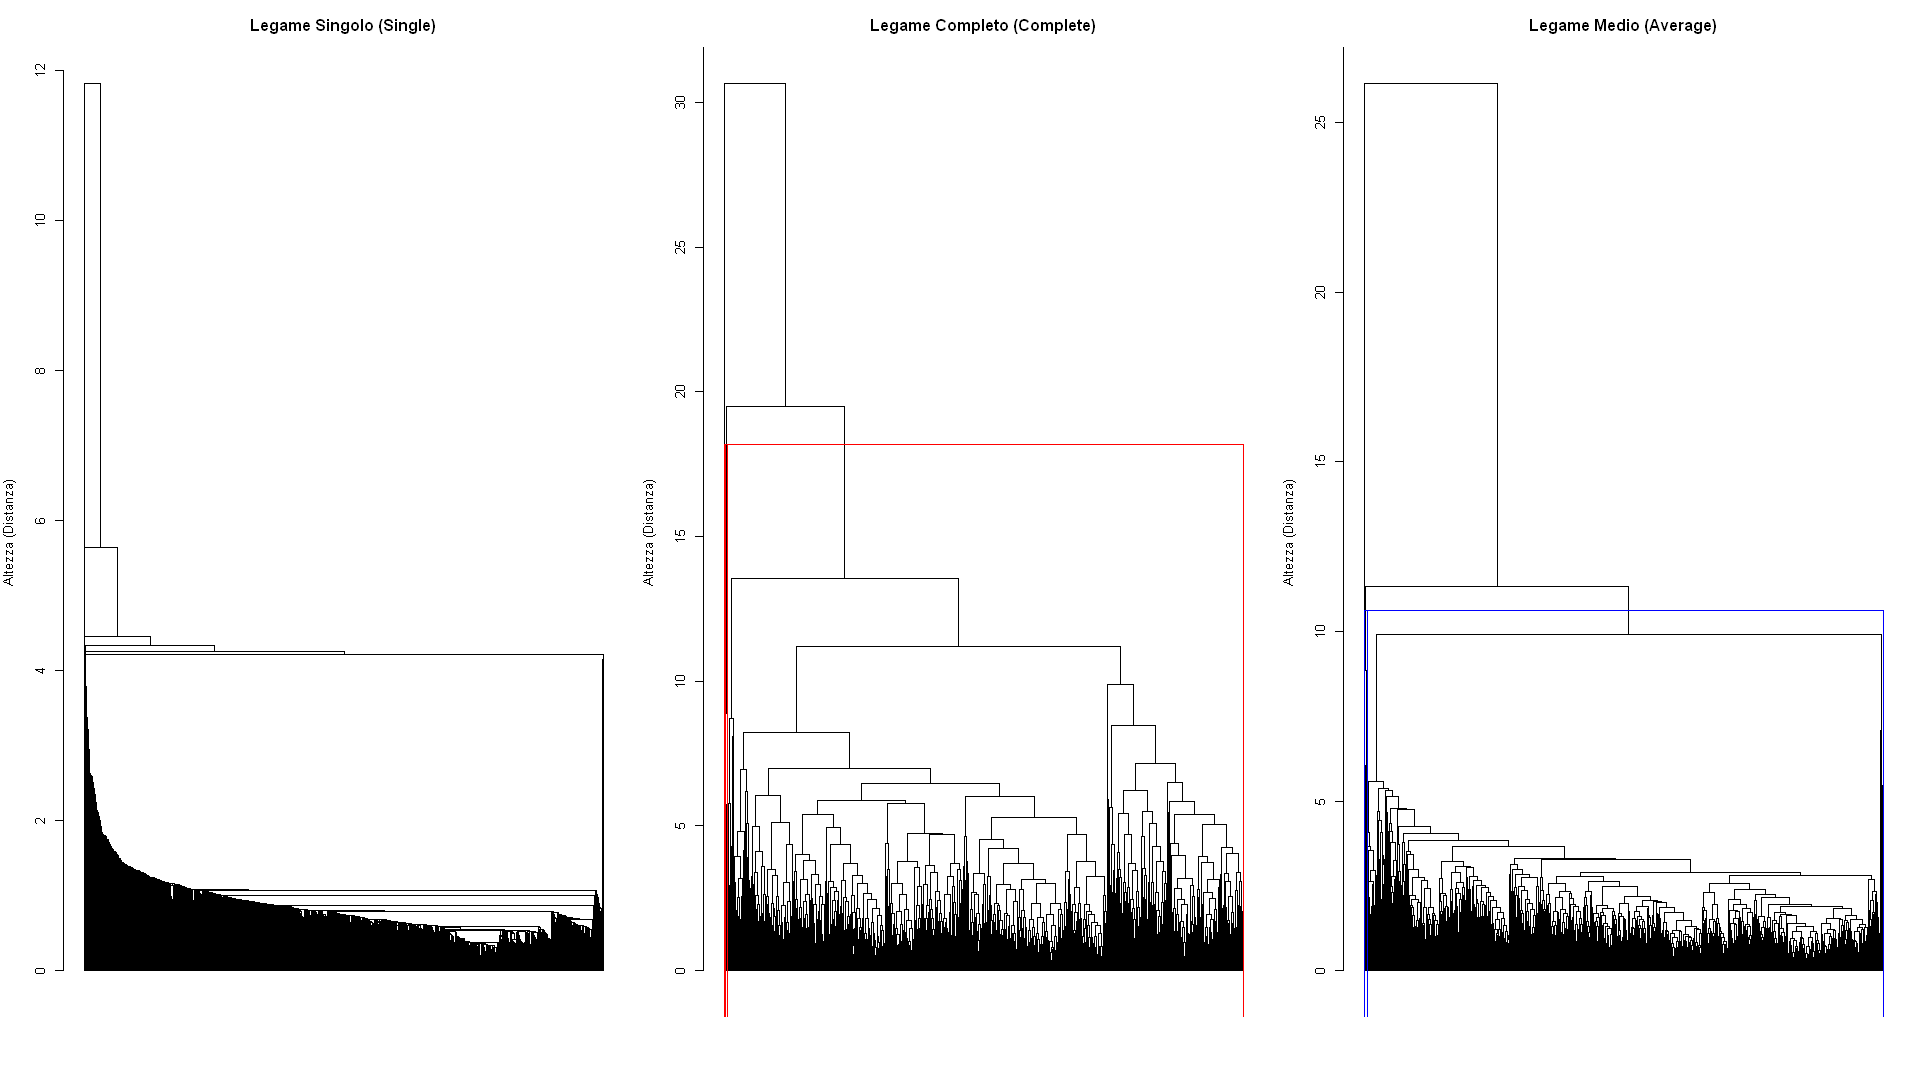

In [4]:
set.seed(42)
sample_size <- 2000
sample_idx <- sample(1:nrow(df_scaled), sample_size)
df_sample_scaled <- df_scaled[sample_idx, ]

# Matrice delle distanze euclidee
d_matrix <- dist(df_sample_scaled, method = "euclidean")

# Applicazione dei metodi gerarchici
hc_single   <- hclust(d_matrix, method = "single")
hc_complete <- hclust(d_matrix, method = "complete")
hc_average  <- hclust(d_matrix, method = "average")

# Visualizzazione dei dendrogrammi
par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
plot(hc_single, labels = FALSE, hang = -1, 
     main = "Legame Singolo (Single)", xlab = "", ylab = "Altezza (Distanza)", sub = "Evidente effetto catena (chaining)")
plot(hc_complete, labels = FALSE, hang = -1, 
     main = "Legame Completo (Complete)", xlab = "", ylab = "Altezza (Distanza)", sub = "Cluster ben definiti e compatti")
rect.hclust(hc_complete, k = 3, border = "red")
plot(hc_average, labels = FALSE, hang = -1, 
     main = "Legame Medio (Average)", xlab = "", ylab = "Altezza (Distanza)", sub = "Compromesso bilanciato")
rect.hclust(hc_average, k = 3, border = "blue")
par(mfrow = c(1, 1))


### 5. Screeplot delle Altezze di Agglomerazione

Lo screeplot delle altezze di fusione negli ultimi passi gerarchici permette di individuare le discontinuità più marcate, indicando il livello di aggregazione naturale prima che vengano fusi gruppi marcatamente eterogenei.


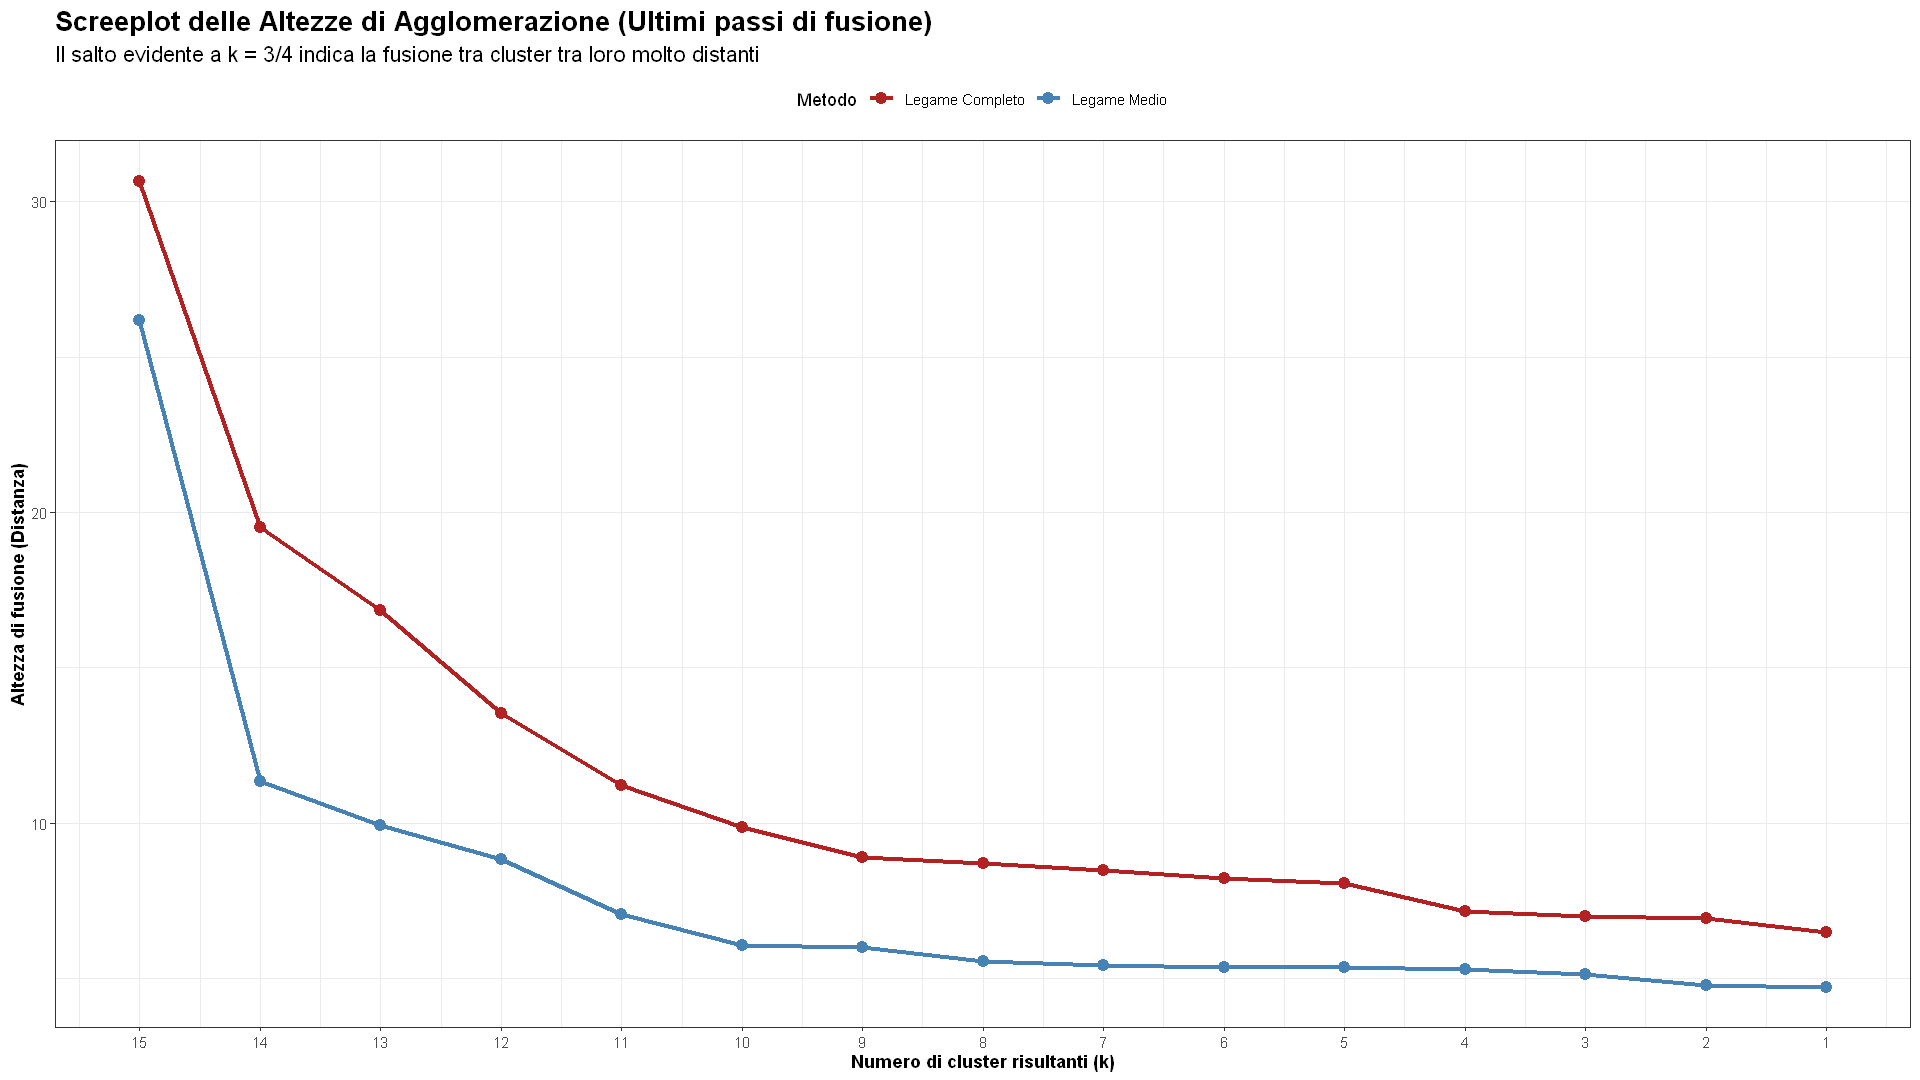

In [5]:
# Estrazione delle ultime altezze di fusione per Complete e Average Linkage
n_steps <- 15
heights_df <- data.frame(
  Cluster_Candidati = rep(n_steps:1, 2),
  Altezza = c(rev(tail(hc_complete$height, n_steps)), rev(tail(hc_average$height, n_steps))),
  Metodo = rep(c("Legame Completo", "Legame Medio"), each = n_steps)
)

ggplot(heights_df, aes(x = Cluster_Candidati, y = Altezza, color = Metodo, group = Metodo)) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  scale_x_reverse(breaks = 1:n_steps) +
  labs(title = "Screeplot delle Altezze di Agglomerazione (Ultimi passi di fusione)",
       subtitle = "Il salto evidente a k = 3/4 indica la fusione tra cluster tra loro molto distanti",
       x = "Numero di cluster risultanti (k)",
       y = "Altezza di fusione (Distanza)") +
  scale_color_manual(values = c("Legame Completo" = "firebrick", "Legame Medio" = "steelblue")) +
  theme(legend.position = "top")


### 6. Clustering Partitivo: K-Means sull'Intero Dataset

L'algoritmo K-Means non richiede il pre-calcolo della matrice di distanza e scala linearmente con il numero di osservazioni, permettendo l'elaborazione dell'intero dataset ($N = 99.323$).

Valutiamo le partizioni da $k = 2$ a $k = 7$ tramite:
1. **Elbow Method**: andamento della devianza intra-cluster ($WCSS$).
2. **Indice di Calinski-Harabasz**: rapporto tra devianza inter-cluster e intra-cluster ponderato per i gradi di libertà.
3. **Silhouette Media**: coesione interna e separazione reciproca (calcolata su campione rappresentativo di 5.000 osservazioni).


In [6]:
k_range <- 2:7
n_obs <- nrow(df_scaled)

kmeans_eval <- data.frame(
  k = k_range,
  WCSS = numeric(length(k_range)),
  BCSS = numeric(length(k_range)),
  TSS = numeric(length(k_range)),
  Perc_Devianza_Spiegata = numeric(length(k_range)),
  Calinski_Harabasz = numeric(length(k_range))
)

# Calcolo K-means per k da 2 a 7
set.seed(42)
for (i in seq_along(k_range)) {
  k_val <- k_range[i]
  km_fit <- kmeans(df_scaled, centers = k_val, nstart = 10, iter.max = 30)
  
  wcss <- km_fit$tot.withinss
  bcss <- km_fit$betweenss
  tss  <- km_fit$totss
  ch   <- (bcss / (k_val - 1)) / (wcss / (n_obs - k_val))
  
  kmeans_eval$WCSS[i] <- round(wcss, 1)
  kmeans_eval$BCSS[i] <- round(bcss, 1)
  kmeans_eval$TSS[i] <- round(tss, 1)
  kmeans_eval$Perc_Devianza_Spiegata[i] <- round((bcss / tss) * 100, 2)
  kmeans_eval$Calinski_Harabasz[i] <- round(ch, 1)
}

# Calcolo Silhouette media su un campione rappresentativo (N = 5000)
set.seed(123)
sil_sample_idx <- sample(1:nrow(df_scaled), 5000)
d_sil_sample <- dist(df_scaled[sil_sample_idx, ], method = "euclidean")

sil_scores <- numeric(length(k_range))
for (i in seq_along(k_range)) {
  k_val <- k_range[i]
  set.seed(42)
  km_sil <- kmeans(df_scaled[sil_sample_idx, ], centers = k_val, nstart = 10)
  sil_obj <- silhouette(km_sil$cluster, d_sil_sample)
  sil_scores[i] <- mean(sil_obj[, 3])
}

kmeans_eval$Silhouette_Media <- round(sil_scores, 3)
kmeans_eval


k,WCSS,BCSS,TSS,Perc_Devianza_Spiegata,Calinski_Harabasz,Silhouette_Media
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,667937.0,126639.0,794576,15.94,18831.0,0.209
3,600294.0,194282.0,794576,24.45,16072.2,0.162
4,541473.6,253102.4,794576,31.85,15475.0,0.169
5,497195.8,297380.2,794576,37.43,14850.9,0.176
6,461122.4,333453.6,794576,41.97,14363.9,0.183
7,429190.6,365385.4,794576,45.98,14091.9,0.173


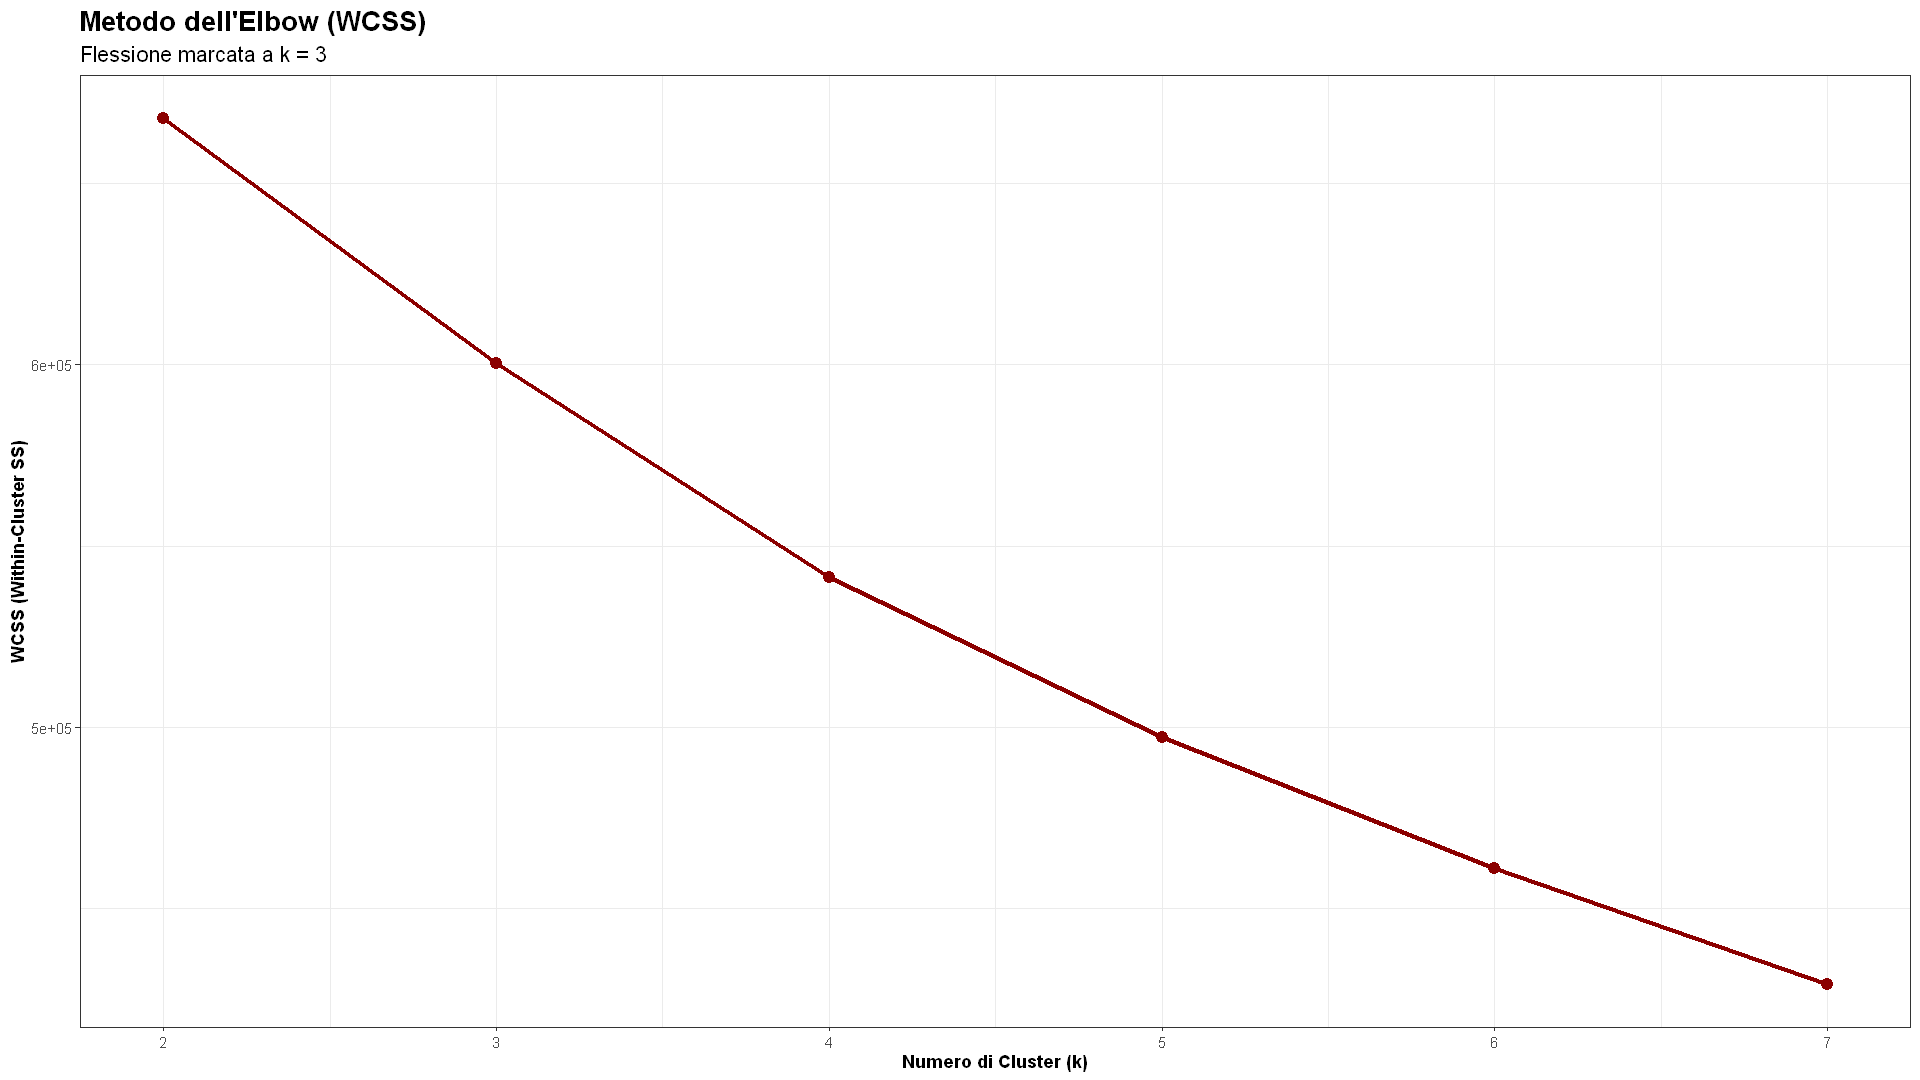

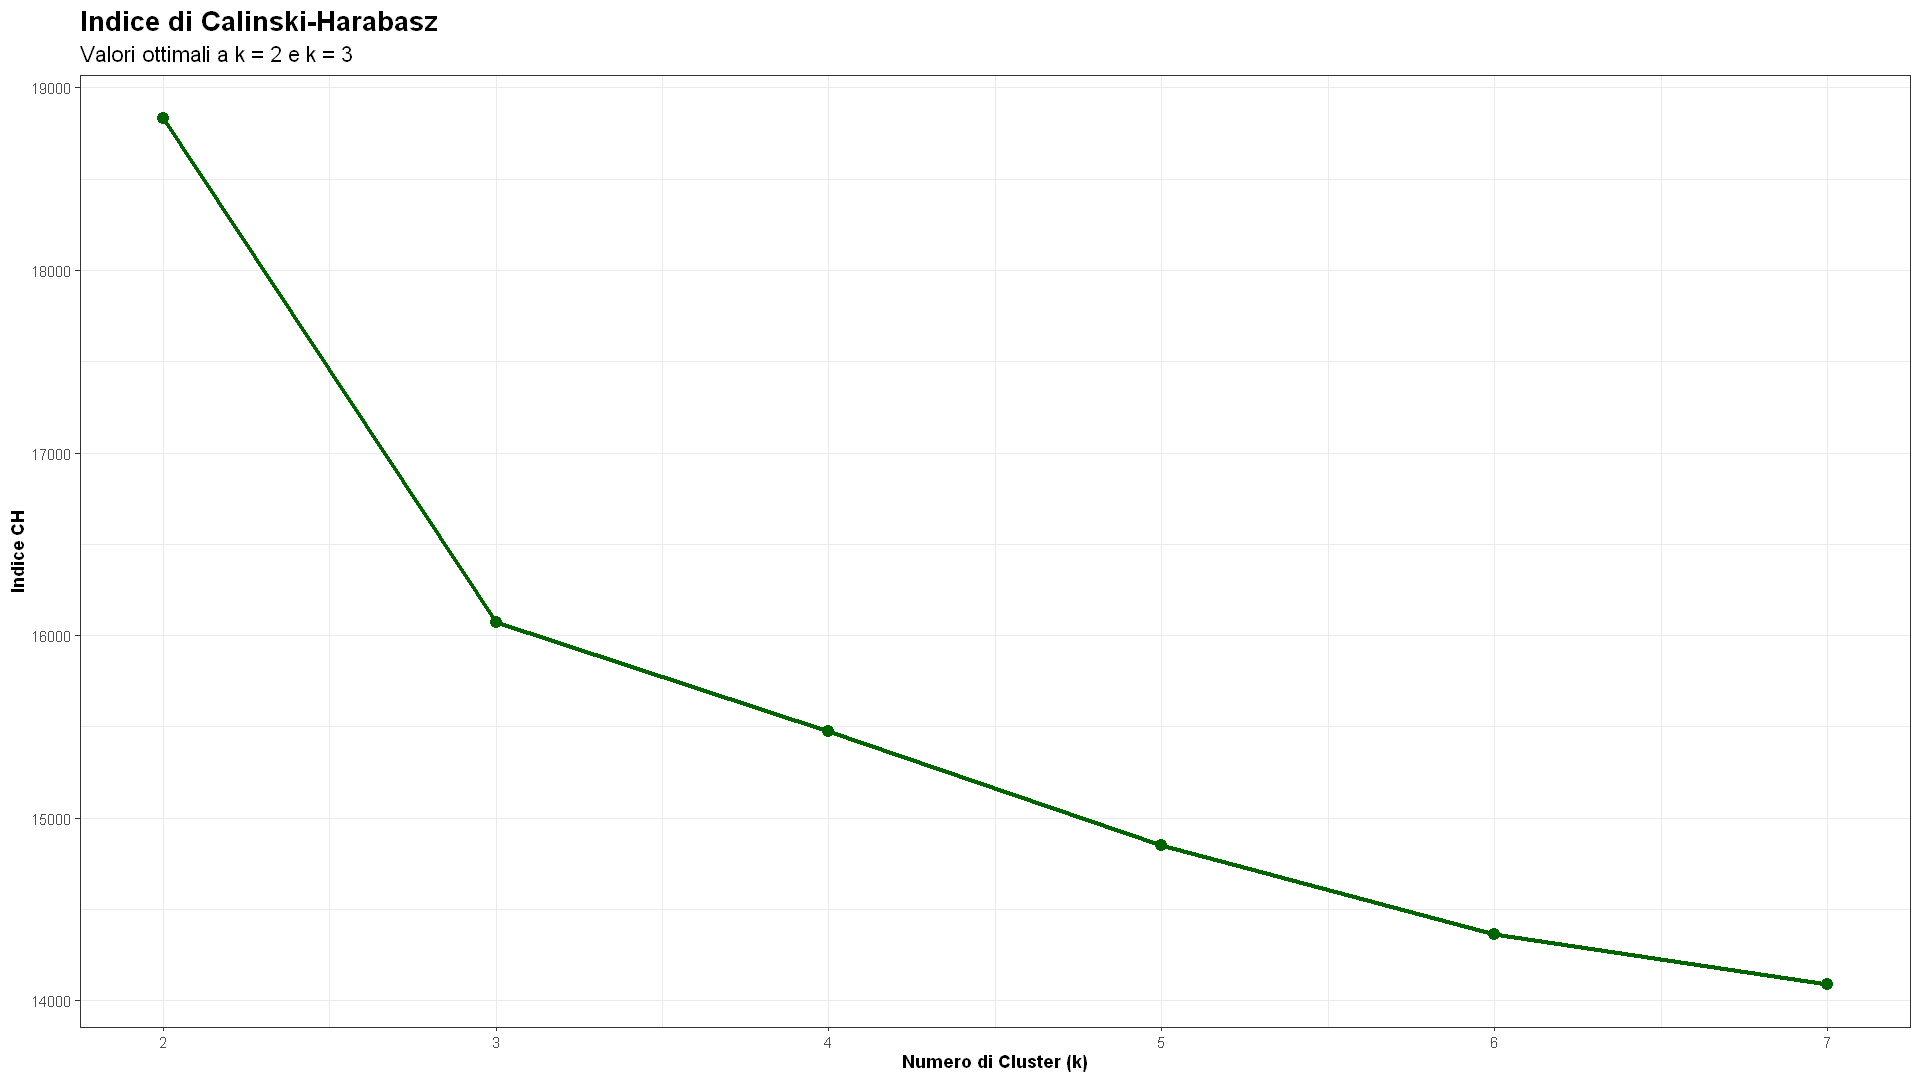

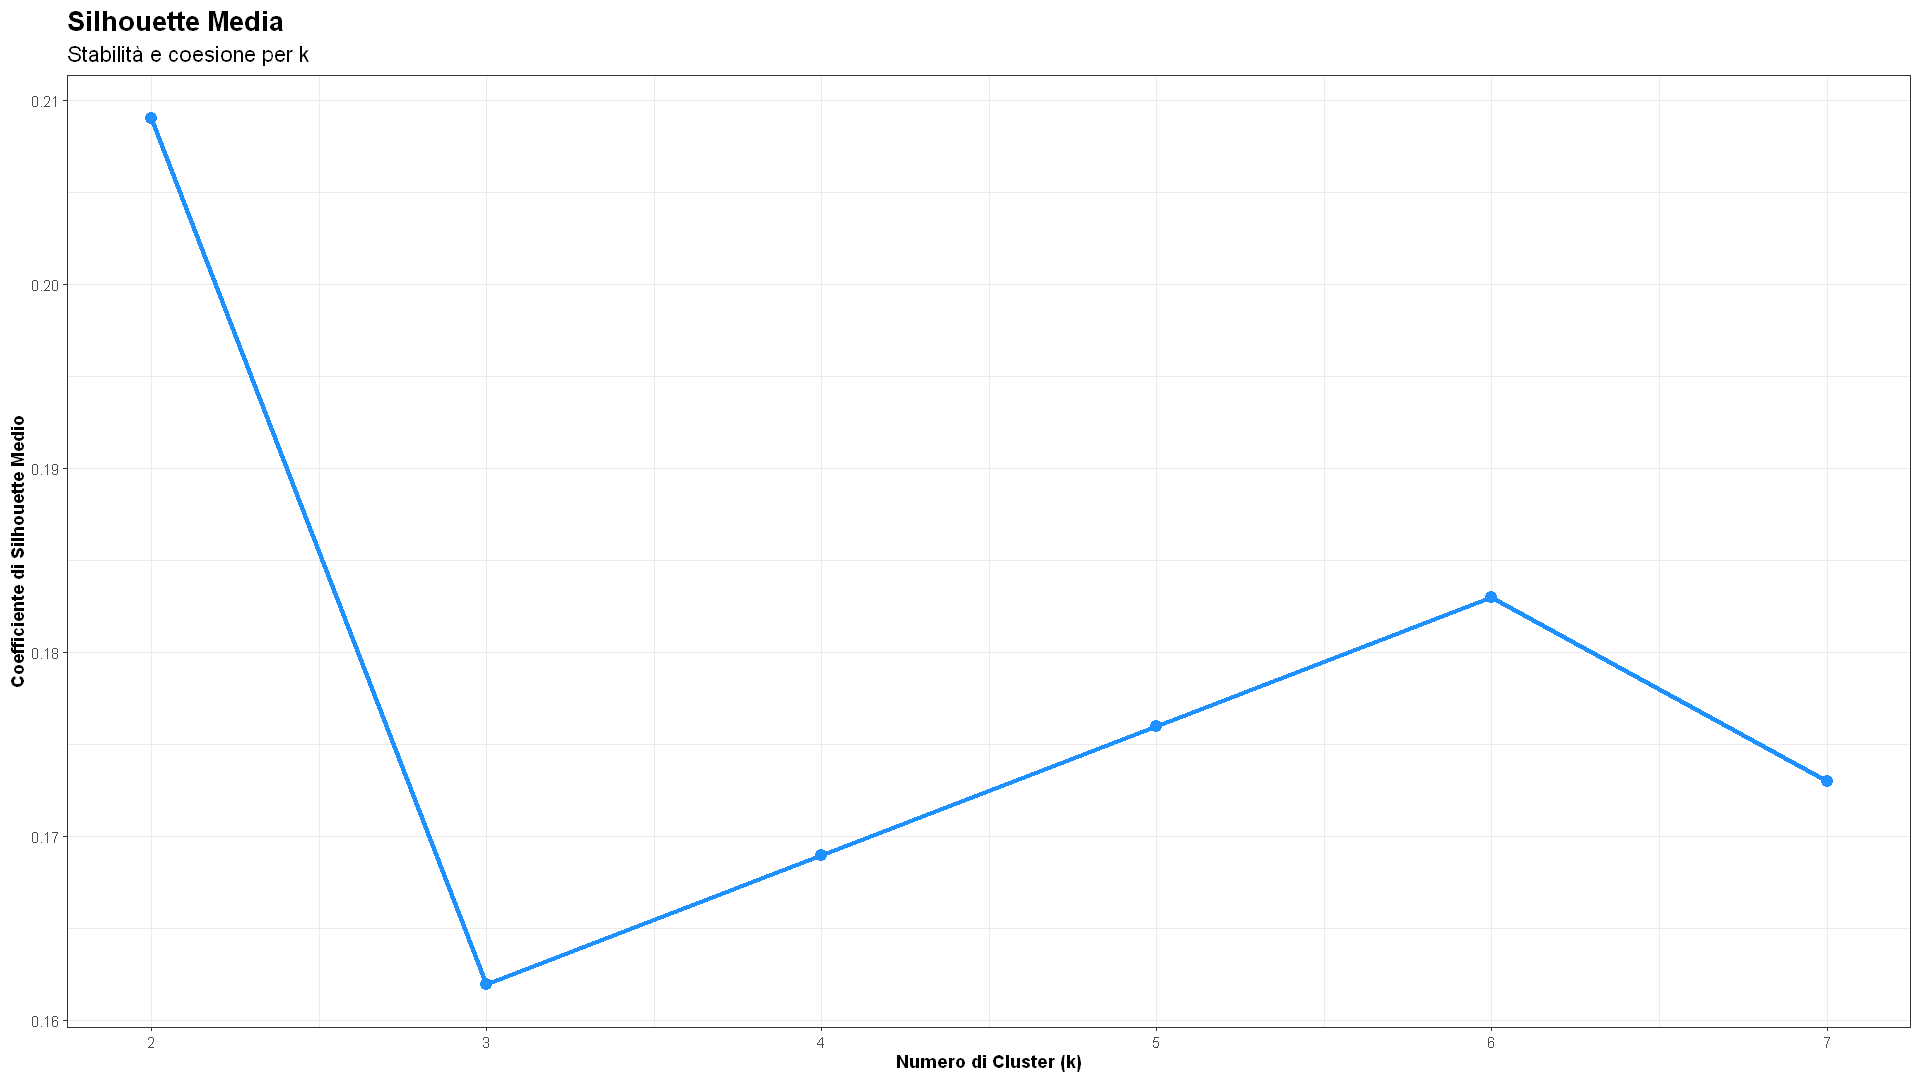

In [7]:
# Grafici dei criteri di valutazione
p_elbow <- ggplot(kmeans_eval, aes(x = k, y = WCSS)) +
  geom_line(color = "darkred", linewidth = 1.2) +
  geom_point(color = "darkred", size = 3) +
  scale_x_continuous(breaks = k_range) +
  labs(title = "Metodo dell'Elbow (WCSS)",
       subtitle = "Flessione marcata a k = 3",
       x = "Numero di Cluster (k)",
       y = "WCSS (Within-Cluster SS)")

p_ch <- ggplot(kmeans_eval, aes(x = k, y = Calinski_Harabasz)) +
  geom_line(color = "darkgreen", linewidth = 1.2) +
  geom_point(color = "darkgreen", size = 3) +
  scale_x_continuous(breaks = k_range) +
  labs(title = "Indice di Calinski-Harabasz",
       subtitle = "Valori ottimali a k = 2 e k = 3",
       x = "Numero di Cluster (k)",
       y = "Indice CH")

p_sil <- ggplot(kmeans_eval, aes(x = k, y = Silhouette_Media)) +
  geom_line(color = "dodgerblue", linewidth = 1.2) +
  geom_point(color = "dodgerblue", size = 3) +
  scale_x_continuous(breaks = k_range) +
  labs(title = "Silhouette Media",
       subtitle = "Stabilità e coesione per k",
       x = "Numero di Cluster (k)",
       y = "Coefficiente di Silhouette Medio")

print(p_elbow)
print(p_ch)
print(p_sil)


### 7. Scelta di $k = 3$, Modello Finale e Decomposizione della Devianza

I tre criteri convergono verso una partizione a **$k = 3$**:
* Il $WCSS$ evidenzia un punto di flessione netto a $k = 3$.
* L'indice di Calinski-Harabasz raggiunge valori elevati a $k = 2$ e $k = 3$.
* Lo screeplot gerarchico mostra un salto marcato nelle ultime fusioni.
* La soluzione a 3 cluster garantisce un ottimo bilanciamento tra compattezza statistica e interpretabilità clinica.

Eseguiamo il modello definitivo K-Means con **$k = 3$**, impostando `nstart = 25` e `iter.max = 50`.


In [8]:
set.seed(42)
k_opt <- 3
km_final <- kmeans(df_scaled, centers = k_opt, nstart = 25, iter.max = 50)

# Assegnazione cluster al dataframe
df_clean$cluster <- factor(km_final$cluster, levels = 1:3, 
                           labels = c("Cluster 1", "Cluster 2", "Cluster 3"))

# Verifica formale della decomposizione dell'inerzia
cat("=== DECOMPOSIZIONE DELLA DEVIANZA ===\n")
cat(sprintf("Devianza Totale (TSS):                    %12.1f\n", km_final$totss))
cat(sprintf("Devianza Intra-Cluster (WCSS totale):     %12.1f (%.2f%%)\n", 
            km_final$tot.withinss, (km_final$tot.withinss / km_final$totss) * 100))
cat(sprintf("Devianza Inter-Cluster (BCSS):            %12.1f (%.2f%%)\n", 
            km_final$betweenss, (km_final$betweenss / km_final$totss) * 100))
cat(sprintf("Verifica TSS = WCSS + BCSS:               %s\n", 
            isTRUE(all.equal(km_final$totss, km_final$tot.withinss + km_final$betweenss))))

cat("\nDistribuzione numerica dei ricoveri nei cluster:\n")
cluster_sizes <- table(df_clean$cluster)
cluster_prop <- prop.table(cluster_sizes) * 100
data.frame(
  Cluster = names(cluster_sizes),
  Numero_Ricoveri = as.numeric(cluster_sizes),
  Percentuale = sprintf("%.2f%%", cluster_prop)
)


=== DECOMPOSIZIONE DELLA DEVIANZA ===


Devianza Totale (TSS):                        794576.0


Devianza Intra-Cluster (WCSS totale):         600294.0 (75.55%)


Devianza Inter-Cluster (BCSS):                194282.0 (24.45%)


Verifica TSS = WCSS + BCSS:               TRUE



Distribuzione numerica dei ricoveri nei cluster:


Cluster,Numero_Ricoveri,Percentuale
<chr>,<dbl>,<chr>
Cluster 1,60315,60.73%
Cluster 2,8795,8.85%
Cluster 3,30213,30.42%


### 8. Profilazione Clinica dei Cluster (Variabili Numeriche)

Calcoliamo le medie reali (de-standardizzate) delle 8 variabili per ciascun gruppo per identificare i profili assistenziali.


In [9]:
cluster_profile <- df_clean %>%
  group_by(cluster) %>%
  summarise(
    N_Ricoveri = n(),
    Degenza_media_gg = round(mean(time_in_hospital), 2),
    Lab_procedure_medie = round(mean(num_lab_procedures), 2),
    Procedure_medie = round(mean(num_procedures), 2),
    Farmaci_medi = round(mean(num_medications), 2),
    Diagnosi_medie = round(mean(number_diagnoses), 2),
    Inpatient_pregressi = round(mean(number_inpatient), 2),
    Emergency_pregressi = round(mean(number_emergency), 2),
    Outpatient_pregressi = round(mean(number_outpatient), 2)
  )

cluster_profile


cluster,N_Ricoveri,Degenza_media_gg,Lab_procedure_medie,Procedure_medie,Farmaci_medi,Diagnosi_medie,Inpatient_pregressi,Emergency_pregressi,Outpatient_pregressi
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Cluster 1,60315,2.97,36.61,0.90,12.30,6.83,0.33,0.09,0.21
Cluster 2,8795,4.37,44.74,0.83,17.03,8.19,3.29,1.25,2.01
Cluster 3,30213,7.20,54.95,2.34,23.03,8.32,0.47,0.11,0.21


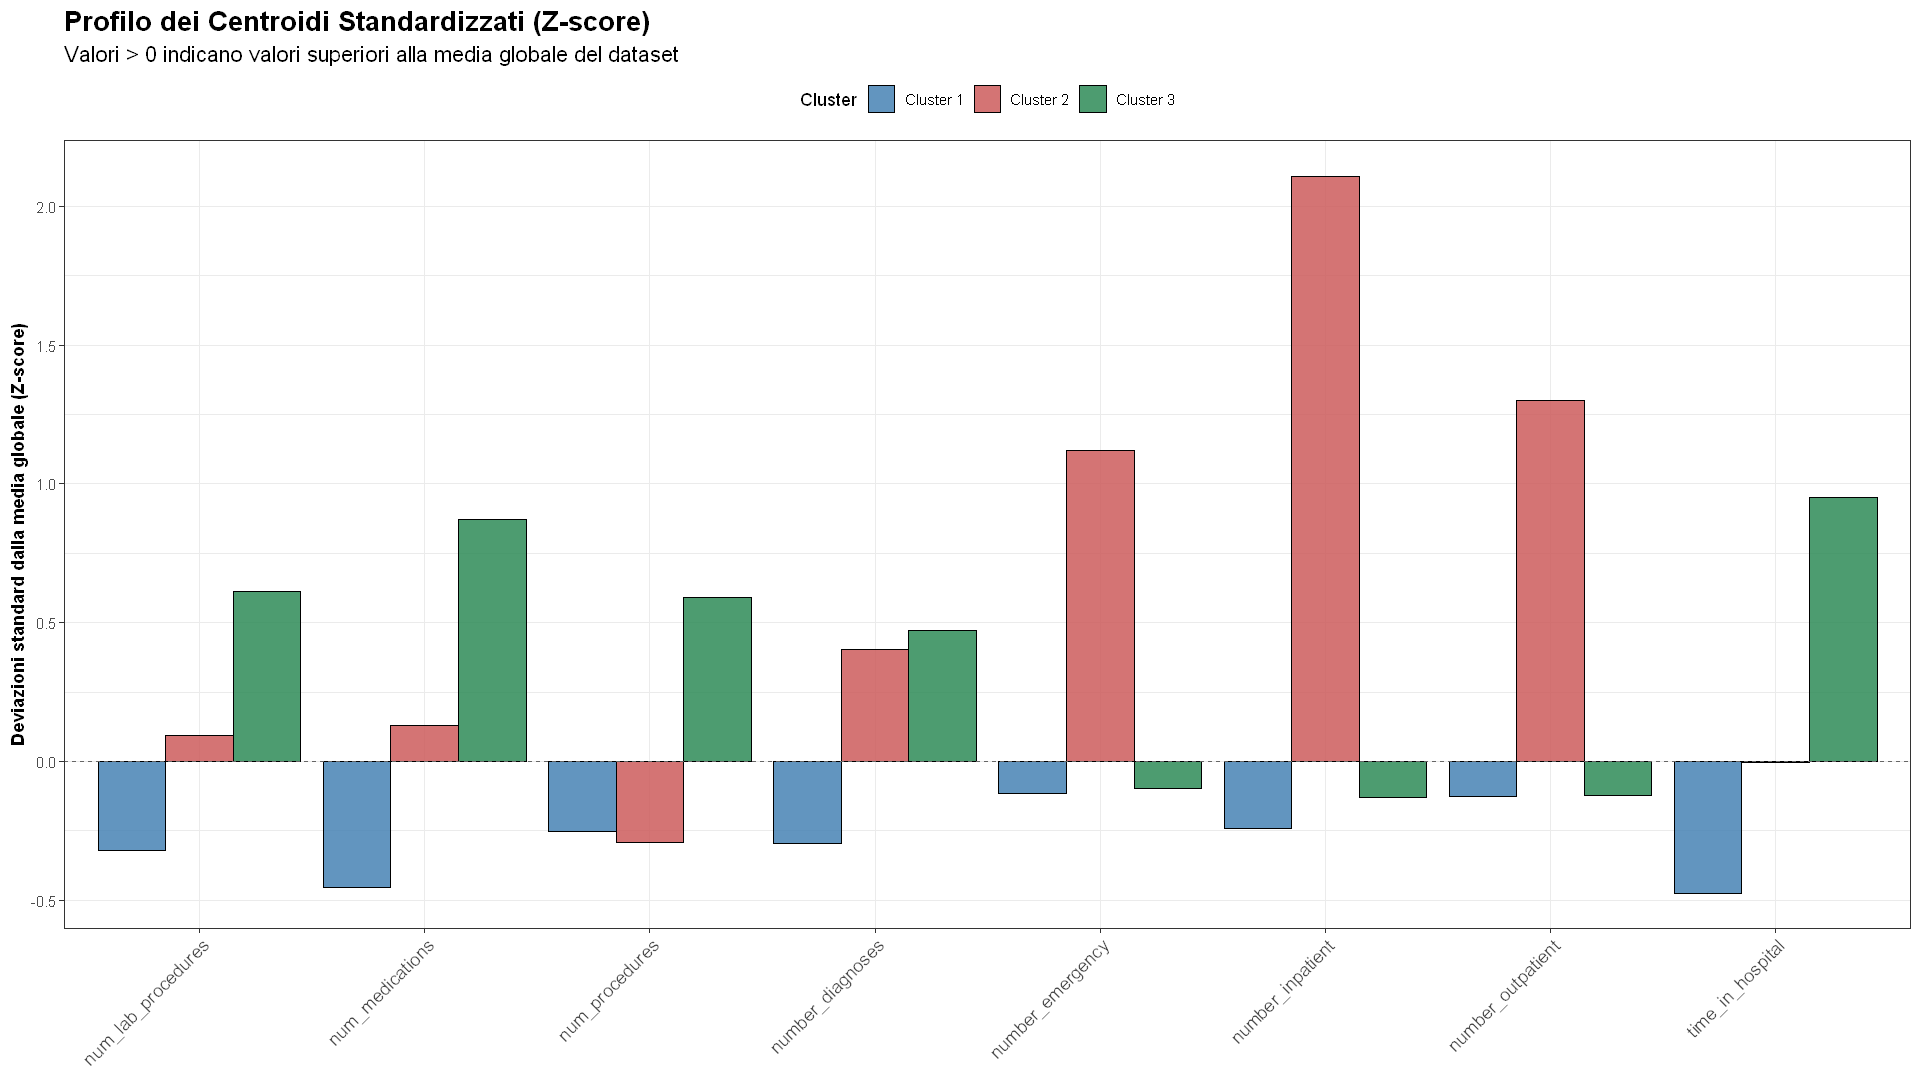

In [10]:
# Visualizzazione dei profili dei centroidi standardizzati
centroids_df <- as.data.frame(km_final$centers)
centroids_df$Cluster <- factor(paste("Cluster", 1:3))

centroids_long <- centroids_df %>%
  pivot_longer(cols = -Cluster, names_to = "Variabile", values_to = "Z_Score")

ggplot(centroids_long, aes(x = Variabile, y = Z_Score, fill = Cluster)) +
  geom_col(position = "dodge", color = "black", alpha = 0.85) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  labs(title = "Profilo dei Centroidi Standardizzati (Z-score)",
       subtitle = "Valori > 0 indicano valori superiori alla media globale del dataset",
       x = NULL, y = "Deviazioni standard dalla media globale (Z-score)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 11),
        legend.position = "top")


### 8b. Visualizzazione Bidimensionale dei Cluster (Proiezione PCA)

Dato che lo spazio originario è a 8 dimensioni, applichiamo l'Analisi delle Componenti Principali (PCA) per proiettare le osservazioni e i centroidi sul piano individuato dalle prime due componenti principali (PC1 e PC2):
* **PC1 (25.3% della varianza)**: polarizzata sull'**intensità clinica acuta del ricovero** (elevati pesi positivi per farmaci, degenza, esami e procedure).
* **PC2 (17.2% della varianza)**: polarizzata sulla **cronicità e sullo storico sanitario pregresso** (elevati pesi positivi per ricoveri ospedalieri precedenti, accessi al pronto soccorso e visite ambulatoriali).

Insieme, PC1 e PC2 spiegano oltre il **42.5%** della variabilità totale.


Varianza spiegata: PC1 = 25.31%, PC2 = 17.15% (Cumulata = 42.46%)



Pesi delle variabili (Loadings) sulle prime due componenti:


                     PC1    PC2
time_in_hospital   0.522 -0.067
num_lab_procedures 0.383 -0.026
num_procedures     0.340 -0.288
num_medications    0.564 -0.087
number_diagnoses   0.356  0.192
number_inpatient   0.121  0.610
number_emergency   0.046  0.591
number_outpatient  0.059  0.382


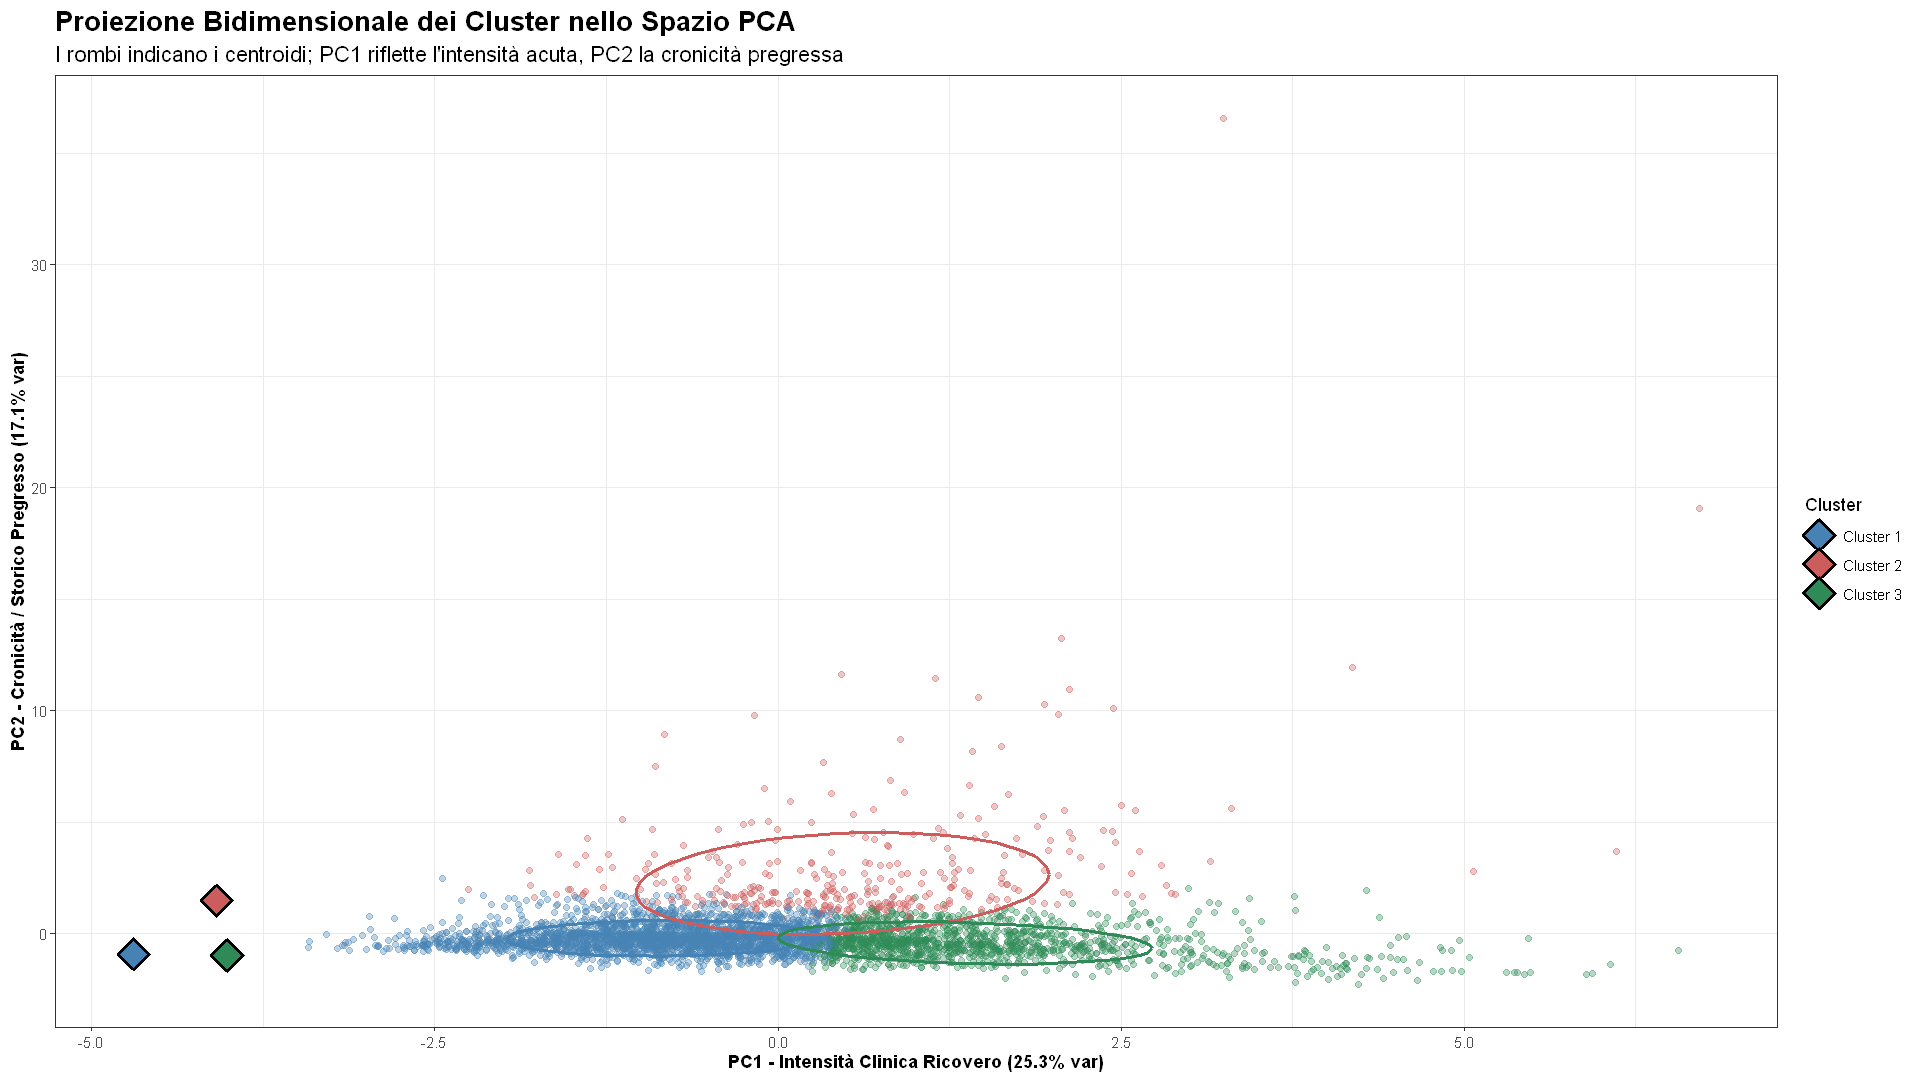

In [11]:
# Calcolo PCA sulle feature standardizzate
pca_fit <- prcomp(df_scaled, center = FALSE, scale. = FALSE)
pca_var <- round((pca_fit$sdev^2 / sum(pca_fit$sdev^2)) * 100, 2)

cat(sprintf("Varianza spiegata: PC1 = %.2f%%, PC2 = %.2f%% (Cumulata = %.2f%%)\n\n", 
            pca_var[1], pca_var[2], pca_var[1] + pca_var[2]))

cat("Pesi delle variabili (Loadings) sulle prime due componenti:\n")
print(round(pca_fit$rotation[, 1:2], 3))

# Campionamento di 4.000 osservazioni per una visualizzazione pulita e reattiva
set.seed(42)
plot_idx <- sample(1:nrow(df_scaled), 4000)
pca_plot_df <- data.frame(
  PC1 = pca_fit$x[plot_idx, 1],
  PC2 = pca_fit$x[plot_idx, 2],
  Cluster = df_clean$cluster[plot_idx]
)

# Proiezione dei centroidi nello spazio PCA
centroids_pca <- as.data.frame(predict(pca_fit, km_final$centers))
centroids_pca$Cluster <- levels(df_clean$cluster)

ggplot(pca_plot_df, aes(x = PC1, y = PC2, color = Cluster)) +
  geom_point(alpha = 0.35, size = 1.6) +
  stat_ellipse(level = 0.75, linewidth = 1.1) +
  geom_point(data = centroids_pca, aes(x = PC1, y = PC2, fill = Cluster),
             size = 6, shape = 23, color = "black", stroke = 1.5) +
  scale_color_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  labs(title = "Proiezione Bidimensionale dei Cluster nello Spazio PCA",
       subtitle = "I rombi indicano i centroidi; PC1 riflette l'intensità acuta, PC2 la cronicità pregressa",
       x = sprintf("PC1 - Intensità Clinica Ricovero (%.1f%% var)", pca_var[1]),
       y = sprintf("PC2 - Cronicità / Storico Pregresso (%.1f%% var)", pca_var[2])) +
  theme(legend.position = "right")


### 8c. Profilazione dei Cluster sulle Variabili Categoriche (Età, Diagnosi, Insulina)

Per completare il quadro clinico, esaminiamo come i tre cluster si differenziano rispetto a variabili categoriche chiave:
* **Fasce d'età (`age`)**: distribuzione demografica dei pazienti.
* **Diagnosi primaria (`diag_1_category`)**: le 9 macro-categorie cliniche ICD-9.
* **Terapia insulinica (`insulin`)**: presenza e modulazione dell'insulina (Down, No, Steady, Up).


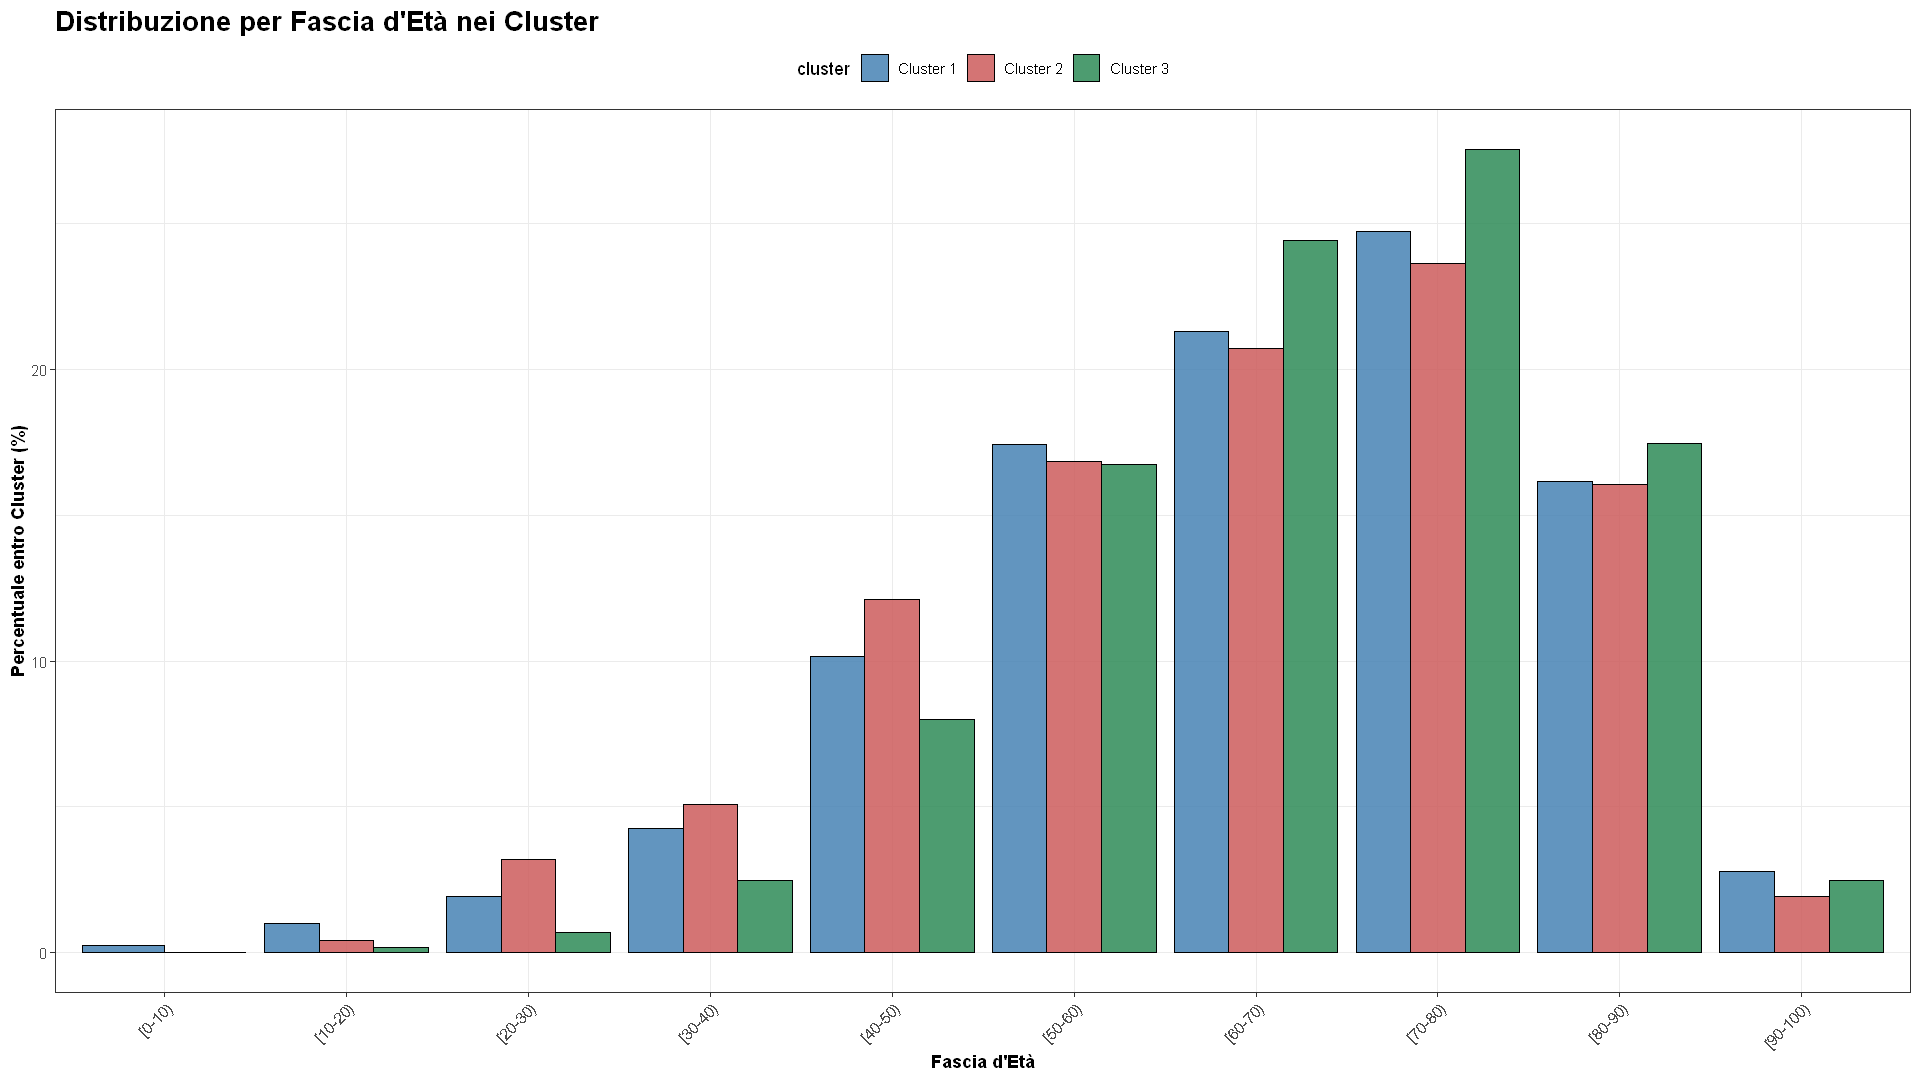

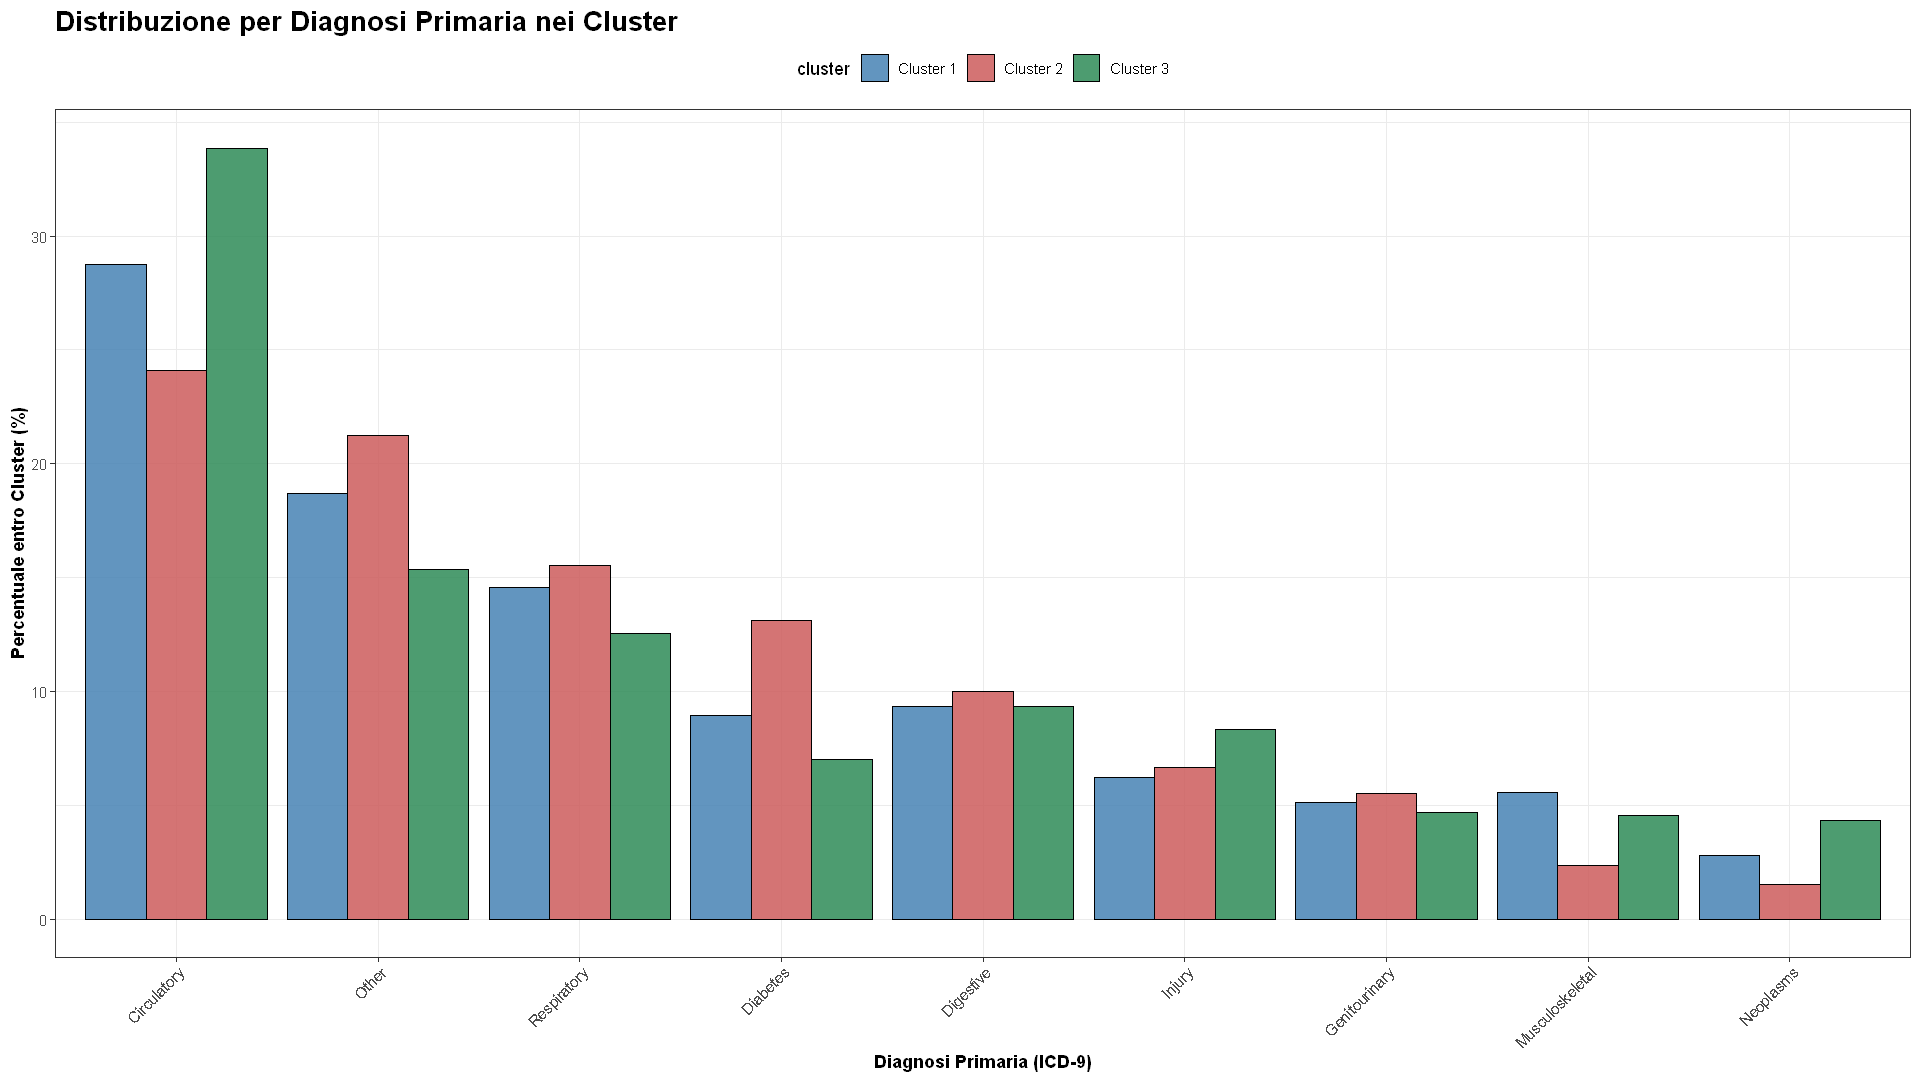

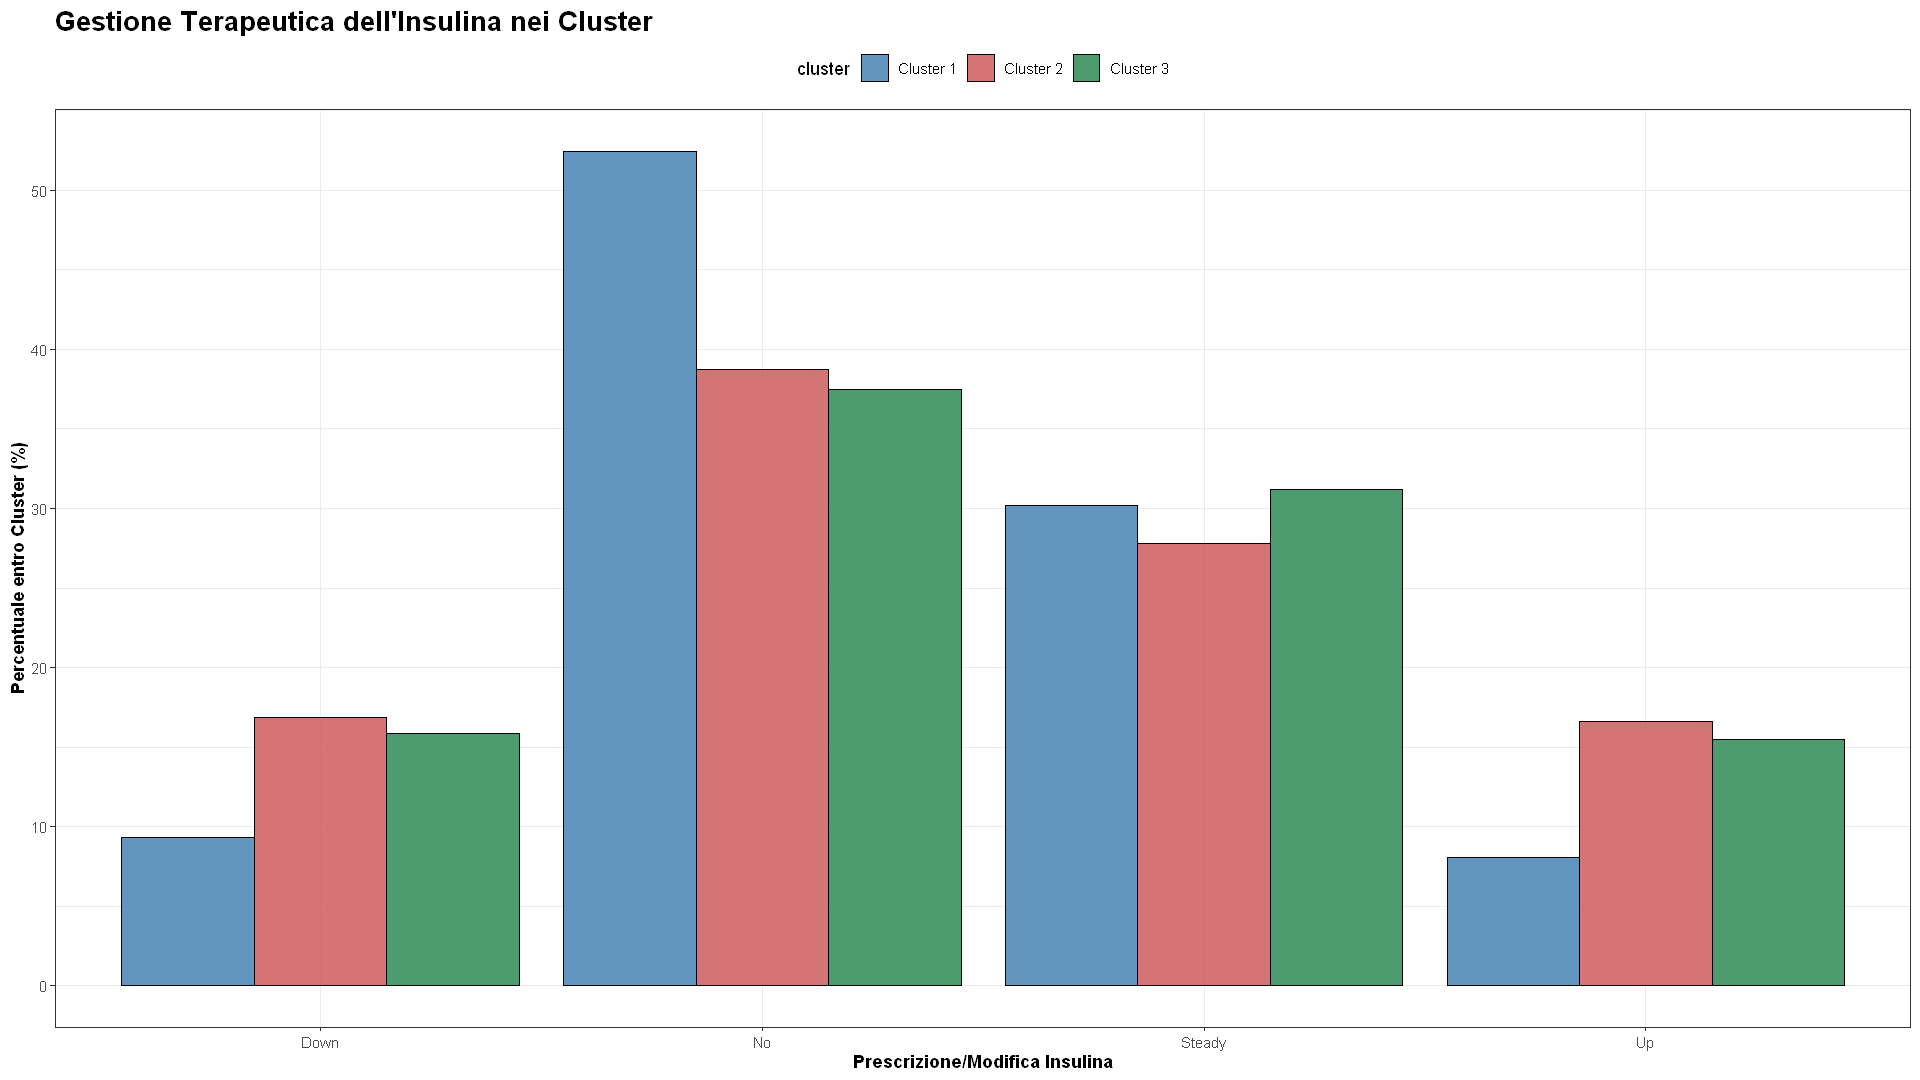

In [12]:
# Ricostruzione della macro-categoria diagnostica primaria
df_clean <- df_clean %>%
  mutate(
    diag_num = suppressWarnings(as.numeric(diag_1)),
    diag_1_category = case_when(
      is.na(diag_1) ~ "Missing",
      str_detect(diag_1, "^[VE]") ~ "Other",
      str_detect(diag_1, "^250") ~ "Diabetes",
      (diag_num >= 390 & diag_num <= 459) | diag_num == 785 ~ "Circulatory",
      (diag_num >= 460 & diag_num <= 519) | diag_num == 786 ~ "Respiratory",
      (diag_num >= 520 & diag_num <= 579) | diag_num == 787 ~ "Digestive",
      (diag_num >= 580 & diag_num <= 629) | diag_num == 788 ~ "Genitourinary",
      diag_num >= 800 & diag_num <= 999 ~ "Injury",
      diag_num >= 710 & diag_num <= 739 ~ "Musculoskeletal",
      diag_num >= 140 & diag_num <= 239 ~ "Neoplasms",
      TRUE ~ "Other"
    )
  )

# 1. Distribuzione per Fascia d'Età
p_age <- df_clean %>%
  count(cluster, age) %>%
  group_by(cluster) %>%
  mutate(pct = (n / sum(n)) * 100) %>%
  ggplot(aes(x = age, y = pct, fill = cluster)) +
  geom_col(position = "dodge", color = "black", alpha = 0.85) +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  labs(title = "Distribuzione per Fascia d'Età nei Cluster",
       x = "Fascia d'Età", y = "Percentuale entro Cluster (%)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "top")

# 2. Distribuzione per Diagnosi Primaria
p_diag <- df_clean %>%
  count(cluster, diag_1_category) %>%
  group_by(cluster) %>%
  mutate(pct = (n / sum(n)) * 100) %>%
  ggplot(aes(x = reorder(diag_1_category, -pct), y = pct, fill = cluster)) +
  geom_col(position = "dodge", color = "black", alpha = 0.85) +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  labs(title = "Distribuzione per Diagnosi Primaria nei Cluster",
       x = "Diagnosi Primaria (ICD-9)", y = "Percentuale entro Cluster (%)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "top")

# 3. Distribuzione per Terapia Insulinica
p_ins <- df_clean %>%
  count(cluster, insulin) %>%
  group_by(cluster) %>%
  mutate(pct = (n / sum(n)) * 100) %>%
  ggplot(aes(x = insulin, y = pct, fill = cluster)) +
  geom_col(position = "dodge", color = "black", alpha = 0.85) +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  labs(title = "Gestione Terapeutica dell'Insulina nei Cluster",
       x = "Prescrizione/Modifica Insulina", y = "Percentuale entro Cluster (%)") +
  theme(legend.position = "top")

print(p_age)
print(p_diag)
print(p_ins)


### Caratterizzazione Clinica dei Tre Cluster:

* **Cluster 1 — Bassa Complessità / Degenza Breve (60,7%)**: degenza ridotta (2.97 giorni), basso carico farmacologico (12.3) e anamnesi quasi priva di ricoveri pregressi (0.33). Oltre il 52% non assume insulina e il decorso è prevalentemente di routine.
* **Cluster 2 — Cronici Frequent Flyers (8,9%)**: storia clinica dominata da frequenti ospedalizzazioni pregresse (media **3.29 ricoveri pregressi**, **1.25 accessi PS**, **2.01 visite ambulatoriali nell'anno**). Presenta la più alta quota di diabete come diagnosi primaria (13.1%) e oltre il 61% di utilizzo di insulina, con frequenti modifiche posologiche (33.4% Up o Down).
* **Cluster 3 — Acuti / Chirurgici Complessi (30,4%)**: degenza prolungata (**7.20 giorni**), elevato numero di procedure (2.34), farmaci (23.0) ed esami di laboratorio (55.0). Età più avanzata (il 69.4% ha oltre 60 anni) e netta prevalenza di patologie circolatorie gravi (33.9%) e neoplasie.


### 9. Validazione Clinica con il Target `readmitted`

Verifichiamo se la partizione non supervisionata discrimina il rischio di riammissione ospedaliera (in particolare a 30 giorni, `<30`).


In [13]:
# Tabella di contingenza assoluta
tab_readm <- table(df_clean$cluster, df_clean$readmitted)
cat("--- Tabella di Contingenza: Cluster vs Riammissione (Conteggi) ---\n")
print(tab_readm)

# Tabella delle percentuali di riga (Tassi per cluster)
tab_prop <- prop.table(tab_readm, margin = 1) * 100
cat("\n--- Percentuali di Riga (% entro ciascun cluster) ---\n")
print(round(tab_prop, 2))

# Test Chi-quadrato di indipendenza
chi_res <- chisq.test(tab_readm)
cat(sprintf("\nTest Chi-quadrato di indipendenza:\n  chi2 = %.1f, df = %d, p-value = %.3e\n", 
            chi_res$statistic, chi_res$parameter, chi_res$p.value))


--- Tabella di Contingenza: Cluster vs Riammissione (Conteggi) ---


           
              <30   >30    NO
  Cluster 1  5599 19808 34908
  Cluster 2  2018  4583  2194
  Cluster 3  3692 11107 15414



--- Percentuali di Riga (% entro ciascun cluster) ---


           
              <30   >30    NO
  Cluster 1  9.28 32.84 57.88
  Cluster 2 22.94 52.11 24.95
  Cluster 3 12.22 36.76 51.02



Test Chi-quadrato di indipendenza:
  chi2 = 3697.3, df = 4, p-value = 0.000e+00


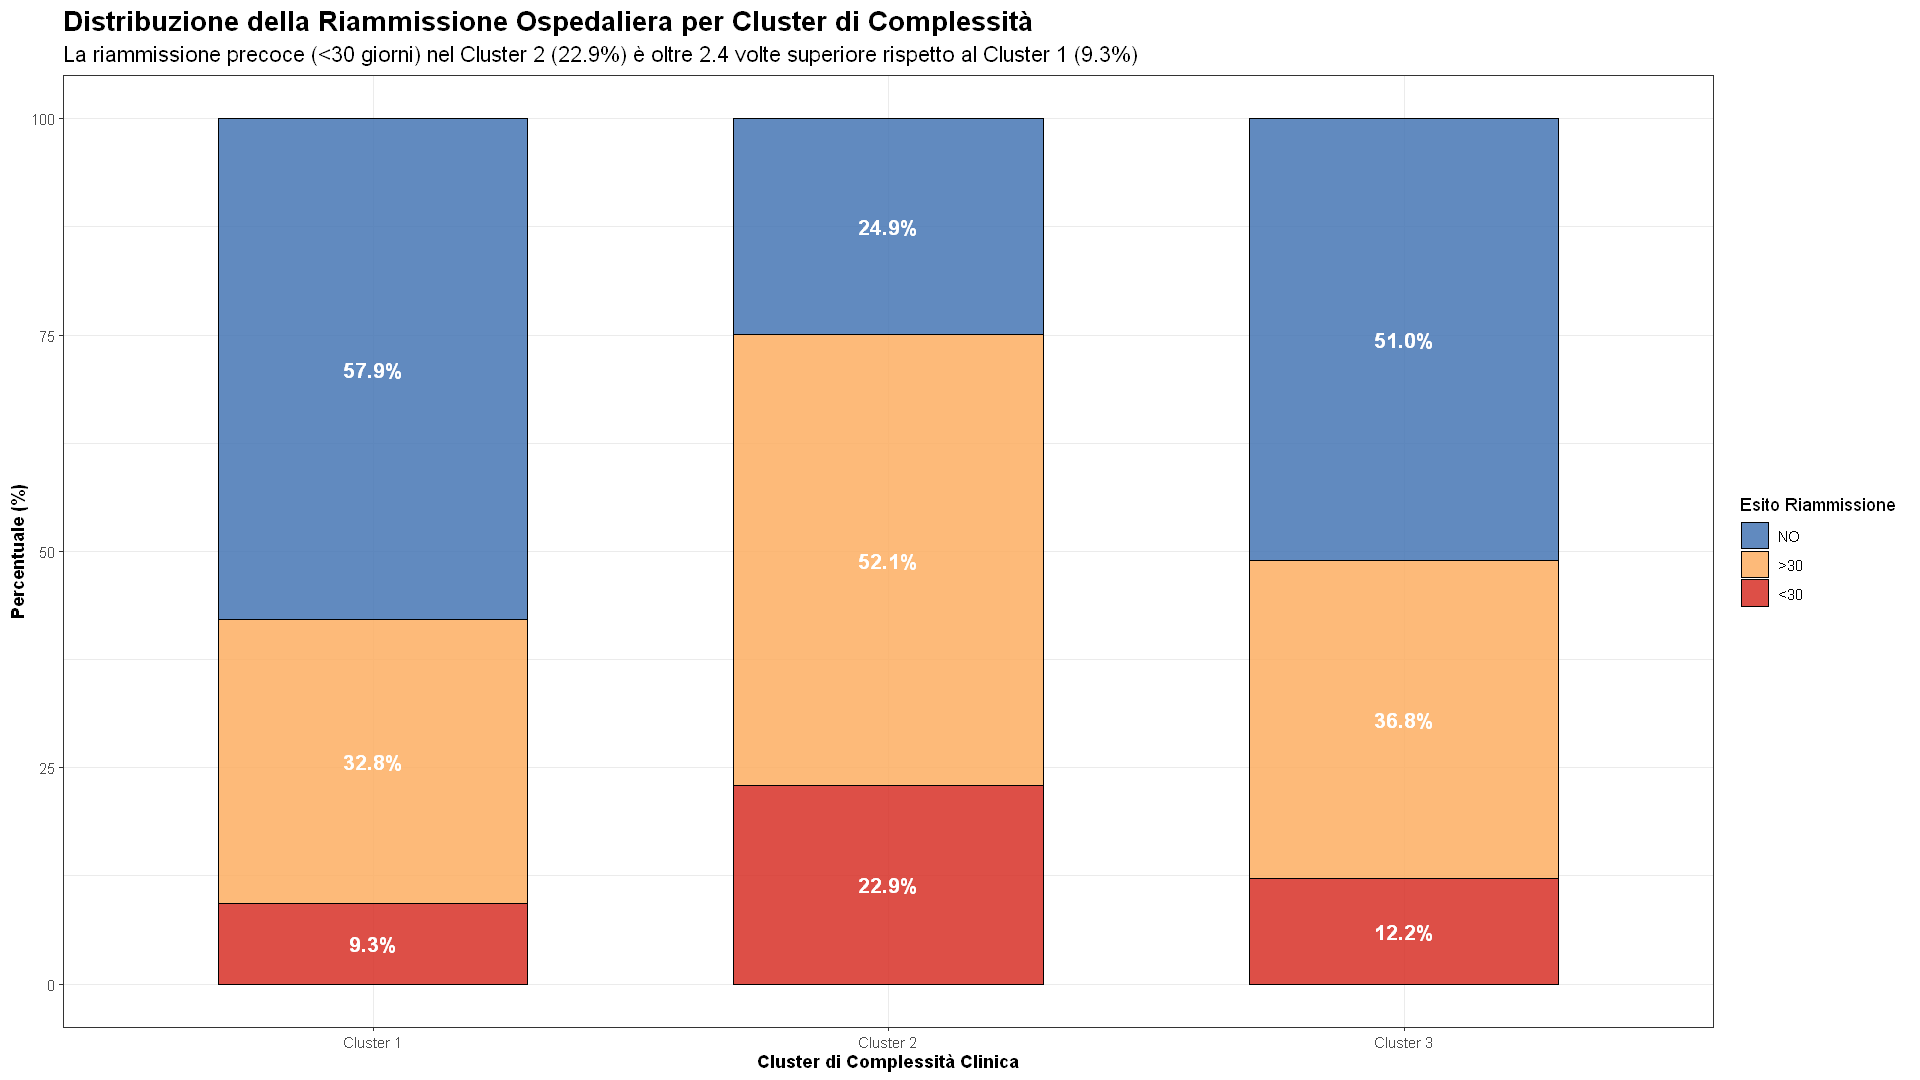

In [14]:
# Rappresentazione grafica della distribuzione di riammissione per cluster
df_plot_readm <- as.data.frame(tab_prop) %>%
  rename(Cluster = Var1, Readmitted = Var2, Percentuale = Freq) %>%
  mutate(Readmitted = factor(Readmitted, levels = c("NO", ">30", "<30")))

ggplot(df_plot_readm, aes(x = Cluster, y = Percentuale, fill = Readmitted)) +
  geom_col(position = "stack", color = "black", alpha = 0.85, width = 0.6) +
  geom_text(aes(label = sprintf("%.1f%%", Percentuale)),
            position = position_stack(vjust = 0.5), size = 4.5, fontface = "bold", color = "white") +
  scale_fill_manual(values = c("NO" = "#4575b4", ">30" = "#fdae61", "<30" = "#d73027")) +
  labs(title = "Distribuzione della Riammissione Ospedaliera per Cluster di Complessità",
       subtitle = "La riammissione precoce (<30 giorni) nel Cluster 2 (22.9%) è oltre 2.4 volte superiore rispetto al Cluster 1 (9.3%)",
       x = "Cluster di Complessità Clinica",
       y = "Percentuale (%)",
       fill = "Esito Riammissione") +
  theme(legend.position = "right")


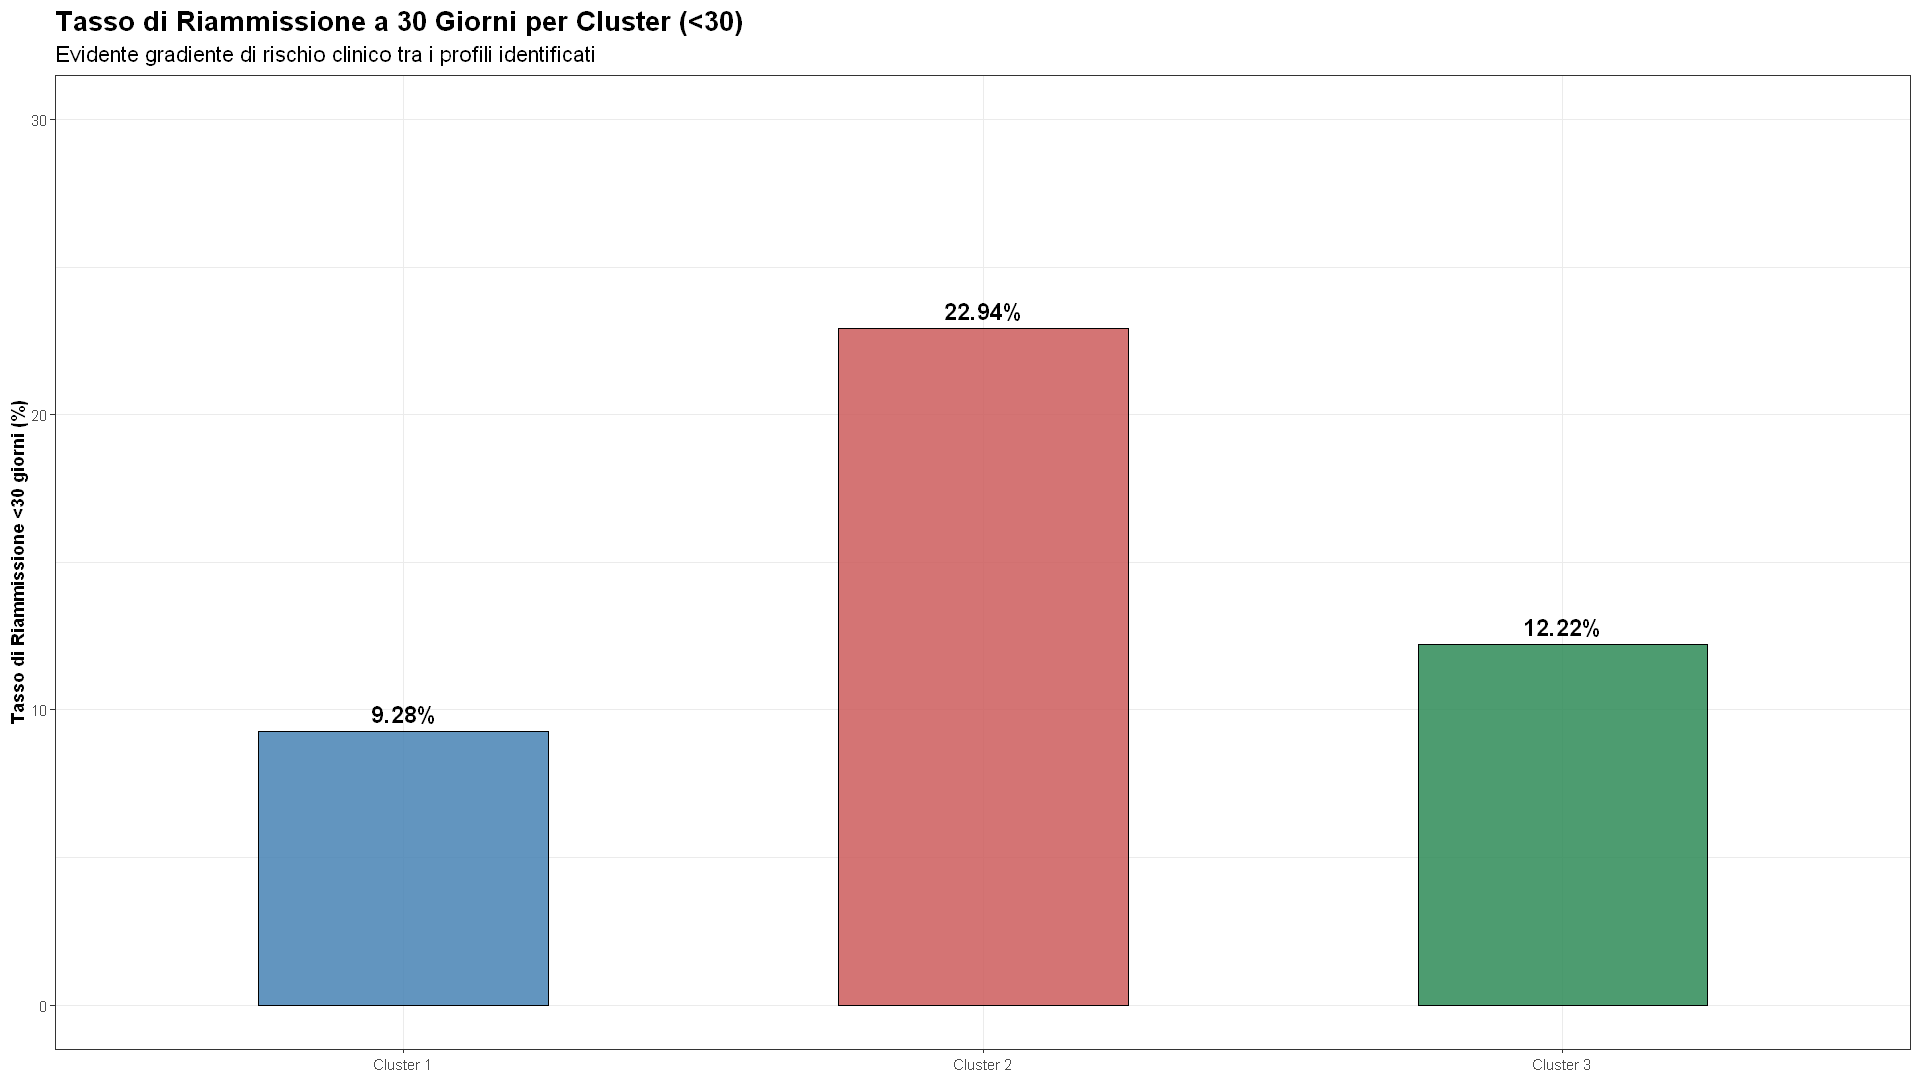

In [15]:
# Focus specifico sul target critico: Tasso di Riammissione Precoce (<30 giorni)
df_readm_30 <- df_clean %>%
  group_by(cluster) %>%
  summarise(
    Totale_Ricoveri = n(),
    Riammessi_30gg = sum(readmitted == "<30"),
    Tasso_30gg = round((Riammessi_30gg / Totale_Ricoveri) * 100, 2)
  )

ggplot(df_readm_30, aes(x = cluster, y = Tasso_30gg, fill = cluster)) +
  geom_col(color = "black", width = 0.5, alpha = 0.85) +
  geom_text(aes(label = sprintf("%.2f%%", Tasso_30gg)), vjust = -0.5, size = 5, fontface = "bold") +
  scale_fill_manual(values = c("Cluster 1" = "steelblue", "Cluster 2" = "indianred", "Cluster 3" = "seagreen")) +
  ylim(0, 30) +
  labs(title = "Tasso di Riammissione a 30 Giorni per Cluster (<30)",
       subtitle = "Evidente gradiente di rischio clinico tra i profili identificati",
       x = NULL, y = "Tasso di Riammissione <30 giorni (%)") +
  theme(legend.position = "none")


### 9b. Analisi Dettagliata della Silhouette per il Modello Finale ($k = 3$)

Per validare la qualità dell'assegnazione individuale alle classi, calcoliamo la silhouette dettagliata delle osservazioni su campione rappresentativo ($N = 3.000$):
* Il coefficiente $s(i) \in [-1, 1]$ misura quanto l'osservazione $i$ sia vicina al proprio cluster rispetto al cluster alternativo più prossimo.
* Valori $s(i) > 0$ indicano osservazioni assegnate correttamente e coerentemente al proprio cluster.


=== METRICHE DI SILHOUETTE PER CLUSTER ===


Cluster 1: numerosità campione = 1822 | silhouette media = 0.274
Cluster 2: numerosità campione =  240 | silhouette media = -0.084
Cluster 3: numerosità campione =  938 | silhouette media = 0.141



Percentuale totale di osservazioni con silhouette positiva: 89.4%


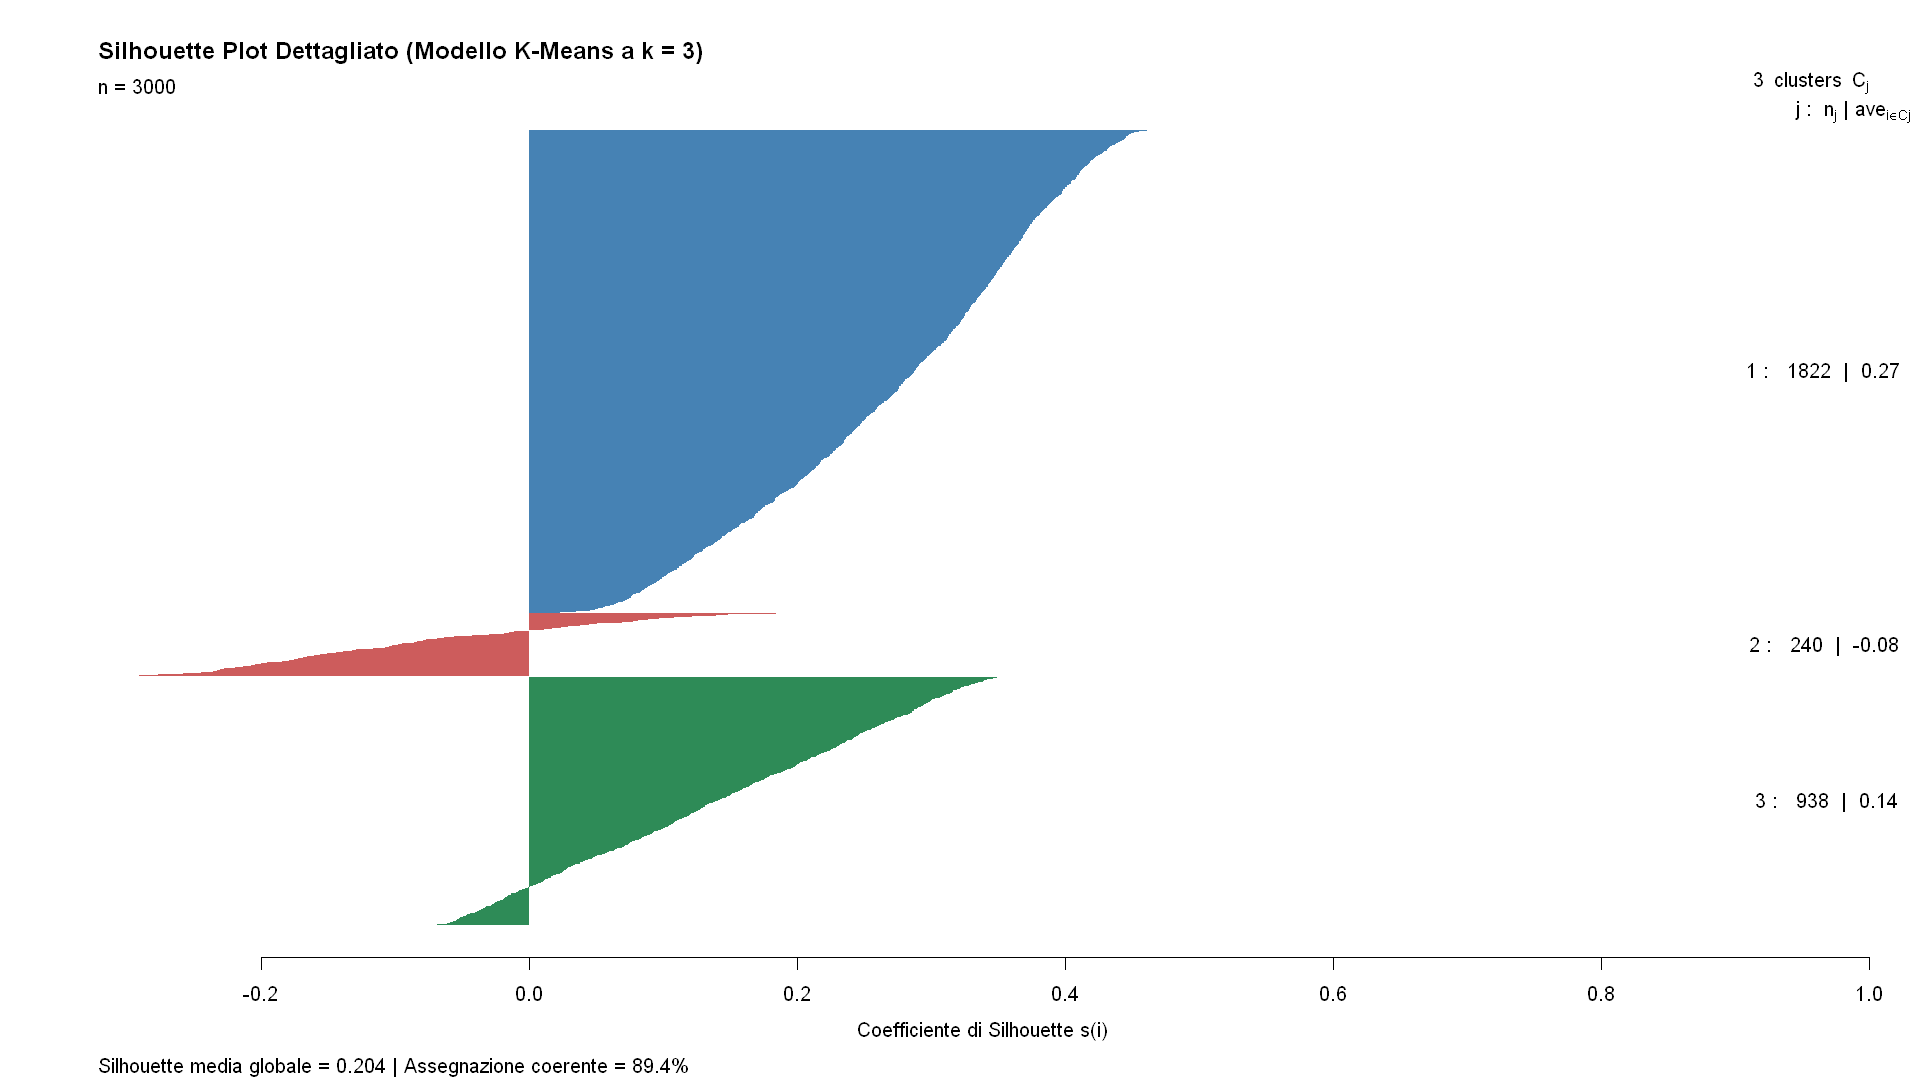

In [16]:
set.seed(123)
sil_n <- 3000
sil_eval_idx <- sample(1:nrow(df_scaled), sil_n)
d_eval_matrix <- dist(df_scaled[sil_eval_idx, ], method = "euclidean")

sil_final_obj <- silhouette(as.numeric(df_clean$cluster[sil_eval_idx]), d_eval_matrix)
sil_final_sum <- summary(sil_final_obj)

cat("=== METRICHE DI SILHOUETTE PER CLUSTER ===\n")
for (cl in 1:3) {
  cat(sprintf("Cluster %d: numerosità campione = %4d | silhouette media = %.3f\n",
              cl, sil_final_sum$clus.sizes[cl], sil_final_sum$clus.avg.widths[cl]))
}

pct_positive <- mean(sil_final_obj[, 3] > 0) * 100
cat(sprintf("\nPercentuale totale di osservazioni con silhouette positiva: %.1f%%\n", pct_positive))

# Silhouette Plot
plot(sil_final_obj, col = c("steelblue", "indianred", "seagreen"), border = NA,
     main = "Silhouette Plot Dettagliato (Modello K-Means a k = 3)",
     xlab = "Coefficiente di Silhouette s(i)", sub = sprintf("Silhouette media globale = %.3f | Assegnazione coerente = %.1f%%", 
                                                            sil_final_sum$avg.width, pct_positive))


### 10. Conclusioni e Sintesi

* La combinazione di standardizzazione, clustering gerarchico esplorativo e K-Means sull'intero dataset ($N = 99.323$) ha isolato tre profili assistenziali netti, spiegando il **24,45%** della devianza multidimensionale complessiva.
* La proiezione bidimensionale PCA ($42.5\%$ di varianza spiegata) conferma l'ortogonalità tra intensità di cura acuta (PC1) e cronicità/frequenza pregressa (PC2).
* L'analisi di silhouette conferma una solida coesione interna, con l'**89,4%** delle osservazioni assegnate a silhouette positiva.
* L'associazione con il target `readmitted` è altamente significativa ($\chi^2 = 3.697,3, p < 10^{-100}$).
* Il **Cluster 2 (Cronici Frequent Flyers)** presenta un tasso di riammissione a 30 giorni del **22,94%** (rispetto al 9,28% del Cluster 1 e al 12,22% del Cluster 3) e un tasso di riammissione globale del **75,05%**.
* Il clustering multivariato raggiunge l'obiettivo prefissato: individuare sottogruppi clinici a elevato rischio di riammissione non rilevabili dall'analisi delle singole variabili isolate.
